# Titanic GenAI workshop: backup code for every step (prompt file titanic v1)

This is the code an assistant would generate for `titanic_workshop_modeling_v1.md`, one cell per step.
Run the cells in order (or Run All). Every step writes its printed output, tables and plots to `reports/`:

- `reports/stepNN_log.txt`: everything the step printed
- `reports/stepNN_<table>.csv`: every table the step reports
- `reports/plots/stepNN_<plot>.png`: every plot

Primary metric: depth needed to capture 80% of survivors (lower is better).
Secondary metric: percent correct with the threshold at the TRAIN base rate (not 0.5).
Data: the first path in `DATA_CANDIDATES` that exists. Python: Anaconda base (scikit-learn, xgboost, scipy, pandas, matplotlib).
Step 10 uses Dean's input shuffling framework (`input_shuffling_v2`) if it can be imported; otherwise a notebook-native version.

## Notebook initialization (problem parameters and global standards: timing, seeds, metadata, report files)

In [1]:
import os, sys, time, json, gc, warnings
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50)

# ---------- PROBLEM PARAMETERS (the block to edit for your own data) ----------
TARGET = "survived"
POSITIVE_CLASS = 1
KNOWN_LEAKAGE_COLUMNS = ["boat", "body"]          # recorded after the outcome was known
ID_LIKE_COLUMNS = ["name", "ticket"]              # used only to derive features
HIGH_CARDINALITY_TEXT = ["cabin", "home.dest"]
CAPTURE_TARGET = 0.80                             # primary metric: depth to capture 80% of positives
TEST_FRACTION = 0.30
RANDOM_STATE = 42
DATA_CANDIDATES = [
    Path("../data/titanic3.csv"),                 # repository layout: data/ next to this folder
    Path("data/titanic3.csv"),
    Path("titanic3.csv"),                         # next to this notebook
    Path.home() / "titanic3.csv",
]
DATA_FILE = next((p for p in DATA_CANDIDATES if p.exists()), None)
assert DATA_FILE is not None, f"data file not found; looked in {[str(p) for p in DATA_CANDIDATES]}"
# Optional: Dean Abbott's input_shuffling package (github.com/abbottanalytics/input_shuffling, licensed AGPL-3.0).
# Clone it next to this repository, or set the INPUT_SHUFFLING_SRC environment variable to its src/ folder.
# If it is not found, the step uses the short notebook-native version below (MIT, like the rest of this repository).
INPUT_SHUFFLING_SRC = next((p for p in [Path(os.environ.get("INPUT_SHUFFLING_SRC", "__none__")), Path("../../input_shuffling/src"),
                                        Path("../input_shuffling/src"), Path("input_shuffling/src")] if p.exists()), Path("input_shuffling/src"))
REPORT_DIR = Path("reports"); PLOT_DIR = REPORT_DIR / "plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)
print("Data file:", DATA_FILE)
print("Reports  :", REPORT_DIR)

# ---------- timing, seed and runtime logs (restart-safe: created only if missing) ----------
if "notebook_timing_log" not in globals(): notebook_timing_log = []
if "random_seed_log" not in globals(): random_seed_log = []

class _Tee:
    """Send printed output to the notebook and to the step's log file."""
    def __init__(self, a, b): self.a, self.b = a, b
    def write(self, s): self.a.write(s); self.b.write(s); return len(s)
    def flush(self): self.a.flush(); self.b.flush()
    def __getattr__(self, k): return getattr(self.a, k)

if "_ORIG_STDOUT" not in globals(): _ORIG_STDOUT = sys.stdout

def step_start(step_number, step_name):
    """Banner, start time, and start teeing output to reports/stepNN_log.txt."""
    global step_start_time, step_start_timestamp, CURRENT_STEP, CURRENT_STEP_NAME, _STEP_LOG
    CURRENT_STEP, CURRENT_STEP_NAME = step_number, step_name
    sys.stdout = _ORIG_STDOUT
    _STEP_LOG = open(REPORT_DIR / f"step{step_number:02d}_log.txt", "w")
    sys.stdout = _Tee(_ORIG_STDOUT, _STEP_LOG)
    step_start_time = time.time(); step_start_timestamp = datetime.now()
    print("=" * 78); print(f"RUNNING STEP {step_number} — {step_name}")
    print(f"Start: {step_start_timestamp:%Y-%m-%d %H:%M:%S}"); print("=" * 78)

def step_end(objects_created="", notes=""):
    """Completion banner, elapsed time, timing row, close the step log."""
    global step_end_time, step_end_timestamp, step_elapsed_seconds, step_elapsed_minutes, notebook_timing_df
    step_end_time = time.time(); step_end_timestamp = datetime.now()
    step_elapsed_seconds = step_end_time - step_start_time; step_elapsed_minutes = step_elapsed_seconds / 60
    notebook_timing_log[:] = [r for r in notebook_timing_log if r["step_number"] != CURRENT_STEP]   # a rerun replaces its own row
    notebook_timing_log.append(dict(step_number=CURRENT_STEP, step_name=CURRENT_STEP_NAME,
        start_timestamp=step_start_timestamp, end_timestamp=step_end_timestamp,
        elapsed_seconds=round(step_elapsed_seconds, 2), elapsed_minutes=round(step_elapsed_minutes, 3), major_runtime_notes=notes))
    notebook_timing_df = pd.DataFrame(notebook_timing_log)
    print("=" * 78); print(f"STEP {CURRENT_STEP} COMPLETE — {step_elapsed_seconds:.1f} s ({step_elapsed_minutes:.2f} min)")
    if objects_created: print("Objects created:", objects_created)
    if notes: print("Notes:", notes)
    print("=" * 78)
    sys.stdout = _ORIG_STDOUT; _STEP_LOG.close()

class timed:
    """Within-step runtime reporting; flags anything over 60 s."""
    def __init__(self, label): self.label = label
    def __enter__(self): self.t = time.time(); return self
    def __exit__(self, *a):
        self.seconds = time.time() - self.t
        print(f"   [{self.label}] {self.seconds:.2f} s" + ("  <-- LONG (>60 s)" if self.seconds > 60 else ""))

def log_seed(step_number, action_name, seed_value, function_or_parameter, notes=""):
    random_seed_log.append(dict(step_number=step_number, action_name=action_name, seed_value=seed_value,
                                function_or_parameter=function_or_parameter, notes=notes))

def show_seeds(step_number):
    d = pd.DataFrame(random_seed_log)
    if len(d):
        d = d[d.step_number == step_number]
        if len(d):
            print("\nRandom seeds used in this step:\n", d.to_string(index=False))
            save_table(d, "random_seeds")

def save_table(df, name, index=False):
    """Write a report table to reports/stepNN_<name>.csv."""
    df.to_csv(REPORT_DIR / f"step{CURRENT_STEP:02d}_{name}.csv", index=index)

def save_fig(fig, name):
    """Save a plot to reports/plots/stepNN_<name>.png and show it."""
    fig.savefig(PLOT_DIR / f"step{CURRENT_STEP:02d}_{name}.png", dpi=90, bbox_inches="tight")
    plt.show(); plt.close(fig)

def show(df, title=None, n=None):
    if title: print(f"\n{title}")
    print((df if n is None else df.head(n)).to_string())

Data file: ../data/titanic3.csv
Reports  : reports


## STEP 0 — ENVIRONMENT SETUP (no analysis yet)
Packages, seed, logs and folders, and one load of the data file named in the problem parameters (kept in memory and saved as Parquet).

In [2]:
step_start(0, "ENVIRONMENT SETUP")
import importlib, random
print("Problem parameters and global standards (Python, seeds, timing, binning/dtypes, prediction storage): will be followed.")
PACKAGES = {"pandas": "pandas", "numpy": "numpy", "scikit-learn": "sklearn", "xgboost": "xgboost",
            "scipy": "scipy", "matplotlib": "matplotlib", "pyarrow": "pyarrow"}
pkg_rows = []
for name, mod in PACKAGES.items():
    try: pkg_rows.append(dict(package=name, version=importlib.import_module(mod).__version__, status="ok"))
    except ImportError: pkg_rows.append(dict(package=name, version="", status="MISSING"))
package_versions_df = pd.DataFrame(pkg_rows); show(package_versions_df, "Packages:"); save_table(package_versions_df, "package_versions")
HAVE_XGBOOST = (package_versions_df.set_index("package").loc["xgboost", "status"] == "ok")
if not HAVE_XGBOOST: print("xgboost is missing: Step 5 will use scikit-learn's GradientBoostingClassifier for the GBM model instead.")
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)
log_seed(0, "global seed", RANDOM_STATE, "random.seed / np.random.seed", "every later step also passes random_state explicitly")
print("Reports folder:", REPORT_DIR, "| plots:", PLOT_DIR)
PARQUET_COPY = REPORT_DIR / "step00_data_copy.parquet"
READERS = {".csv": pd.read_csv, ".tsv": lambda f: pd.read_csv(f, sep="\t"), ".parquet": pd.read_parquet}
with timed("read data file"):
    df_raw = READERS[DATA_FILE.suffix.lower()](DATA_FILE)
df_raw.to_parquet(PARQUET_COPY, index=False)
print(f"Data file: {DATA_FILE} | rows, columns: {df_raw.shape}")
show_seeds(0)
step_end("df_raw (in memory), Parquet copy", "setup only: no audit, no RECORD_ID, no columns dropped")

RUNNING STEP 0 — ENVIRONMENT SETUP
Start: 2026-11-14 23:34:58
Problem parameters and global standards (Python, seeds, timing, binning/dtypes, prediction storage): will be followed.

Packages:
        package version status
0        pandas   2.3.3     ok
1         numpy  1.26.4     ok
2  scikit-learn   1.4.0     ok
3       xgboost   2.0.3     ok
4         scipy  1.10.0     ok
5    matplotlib   3.6.3     ok
6       pyarrow  16.1.0     ok
Reports folder: reports | plots: reports/plots
   [read data file] 0.00 s
Data file: ../data/titanic3.csv | rows, columns: (1309, 14)

Random seeds used in this step:
  step_number action_name  seed_value        function_or_parameter                                                notes
           0 global seed          42 random.seed / np.random.seed every later step also passes random_state explicitly
STEP 0 COMPLETE — 1.0 s (0.02 min)
Objects created: df_raw (in memory), Parquet copy
Notes: setup only: no audit, no RECORD_ID, no columns dropped


## STEP 1 — LOAD DATA AND AUDIT

In [3]:
step_start(1, "LOAD DATA AND AUDIT")
if "df_raw" not in globals():                    # reload only if Step 0's dataframe is gone (kernel restart)
    df_raw = pd.read_parquet(PARQUET_COPY) if PARQUET_COPY.exists() else READERS[DATA_FILE.suffix.lower()](DATA_FILE)
    print("df_raw reloaded.")
else:
    print("Using the dataframe loaded in Step 0.")
for c in df_raw.select_dtypes(include="object"):                       # empty / whitespace-only strings are missing
    df_raw[c] = df_raw[c].str.strip().replace("", np.nan)
if "RECORD_ID" not in df_raw.columns:
    df_raw.insert(0, "RECORD_ID", np.arange(1, len(df_raw) + 1)); print("RECORD_ID created (1..n, file order).")
df_raw = df_raw.set_index("RECORD_ID", drop=False)

print("1) Rows, columns:", df_raw.shape)
print("\n2) Variable names:\n", list(df_raw.columns))
dtypes_df = df_raw.dtypes.astype(str).rename("dtype").to_frame(); show(dtypes_df, "3) Data types:"); save_table(dtypes_df, "dtypes", index=True)
tdist = df_raw[TARGET].value_counts().rename("count").to_frame(); tdist["pct"] = tdist["count"] / len(df_raw)
show(tdist, f"4) {TARGET} distribution (base rate = {df_raw[TARGET].mean():.3f}):"); save_table(tdist, "target_distribution", index=True)
obj_cols = df_raw.select_dtypes(include="object").columns.tolist()
nuniq = df_raw[obj_cols + ["pclass"]].nunique().rename("n_unique").to_frame(); nuniq["pct_of_rows"] = nuniq.n_unique / len(df_raw)
show(nuniq, "5) Unique values of categorical / text variables:"); save_table(nuniq, "unique_values", index=True)
miss = df_raw.isna().sum().rename("n_missing").to_frame(); miss["pct_missing"] = miss.n_missing / len(df_raw)
miss = miss[miss.n_missing > 0].sort_values("n_missing", ascending=False)
show(miss.round(3), "6) Missing values:"); save_table(miss, "missing_values", index=True)
num_cols = [c for c in df_raw.select_dtypes(include=np.number).columns if c not in ("RECORD_ID", TARGET)]
num_stats = df_raw[num_cols].describe().T.rename(columns={"25%": "Q1", "50%": "median", "75%": "Q3", "std": "std_dev"})
show(num_stats.round(2), "7) Numeric summary:"); save_table(num_stats, "numeric_summary", index=True)
rows = []
for c in [c for c in obj_cols + ["pclass", "sibsp", "parch"] if df_raw[c].nunique() <= 20]:
    g = df_raw.groupby(c, dropna=False)[TARGET].agg(records="size", survival_rate="mean").reset_index().rename(columns={c: "level"})
    g.insert(0, "variable", c); rows.append(g)
by_level = pd.concat(rows, ignore_index=True); show(by_level.round(3), "8) Survival rate by level (variables with <= 20 levels):")
save_table(by_level, "survival_by_level")
rows = []
for c in miss.index:
    if c == TARGET: continue
    m = df_raw[c].isna()
    rows.append(dict(variable=c, n_missing=int(m.sum()), rate_when_missing=df_raw.loc[m, TARGET].mean(), rate_when_present=df_raw.loc[~m, TARGET].mean()))
miss_rate = pd.DataFrame(rows); show(miss_rate.round(3), "9) Survival rate with and without a missing value:"); save_table(miss_rate, "survival_by_missingness")

# 10) leakage screen: known leakage columns, plus any column whose presence alone separates the target almost perfectly
rows = []
for c in df_raw.columns.drop(["RECORD_ID", TARGET]):
    present = df_raw[c].notna()
    if present.all() or (~present).all(): continue
    rp, ra = df_raw.loc[present, TARGET].mean(), df_raw.loc[~present, TARGET].mean()
    rows.append(dict(variable=c, rate_when_present=rp, rate_when_missing=ra, gap=abs(rp - ra),
                     flagged=("known (PROBLEM PARAMETERS)" if c in KNOWN_LEAKAGE_COLUMNS else ("proposed: check" if abs(rp - ra) > 0.5 else ""))))
leakage_screen_df = pd.DataFrame(rows).sort_values("gap", ascending=False)
show(leakage_screen_df.round(3), "10) Leakage screen (target rate when the column is present vs missing):"); save_table(leakage_screen_df, "leakage_screen")
print("   boat = lifeboat number, filled almost only for survivors; body = body identification number, only for victims. Both are known only after the outcome.")
id_screen = nuniq[nuniq.pct_of_rows > 0.5].assign(flagged=lambda d: np.where(d.index.isin(ID_LIKE_COLUMNS), "known ID-like", "proposed: check"))
show(id_screen.round(3), "11) Identifier screen (more unique values than half the rows):"); save_table(id_screen, "identifier_screen", index=True)
step_end("df_raw, leakage_screen_df")

RUNNING STEP 1 — LOAD DATA AND AUDIT
Start: 2026-11-14 23:34:59
Using the dataframe loaded in Step 0.
RECORD_ID created (1..n, file order).
1) Rows, columns: (1309, 15)

2) Variable names:
 ['RECORD_ID', 'pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'ticket', 'fare', 'cabin', 'embarked', 'boat', 'body', 'home.dest']

3) Data types:
             dtype
RECORD_ID    int64
pclass       int64
survived     int64
name        object
sex         object
age        float64
sibsp        int64
parch        int64
ticket      object
fare       float64
cabin       object
embarked    object
boat        object
body       float64
home.dest   object

4) survived distribution (base rate = 0.382):
          count       pct
survived                 
0           809  0.618029
1           500  0.381971

5) Unique values of categorical / text variables:
           n_unique  pct_of_rows
name           1307     0.998472
sex               2     0.001528
ticket          929     0.709702
cabin       

## STEP 2 — NON-LEARNED DATA PREPARATION AND FEATURE ENGINEERING

In [4]:
step_start(2, "NON-LEARNED DATA PREPARATION AND FEATURE ENGINEERING")
modeling_prepared_df = df_raw.copy()
# 1) leakage columns stay in the dataframe for reference but are never inputs
print("1) Removed from inputs as leakage:", KNOWN_LEAKAGE_COLUMNS)
# 2) derived features (no learning: each value depends only on its own row, or on the passenger list for ticket counts)
d = modeling_prepared_df
d["title"] = d["name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
d["deck"] = d["cabin"].str[0].fillna("U")
d["cabin_known"] = d["cabin"].notna().astype(int)
d["family_size"] = d["sibsp"] + d["parch"] + 1
d["is_alone"] = (d["family_size"] == 1).astype(int)
d["ticket_group_size"] = d.groupby("ticket")["ticket"].transform("size")
print("2) Derived: title, deck, cabin_known, family_size, is_alone, ticket_group_size.")
print("   ticket_group_size counts passengers sharing a ticket over the whole file. It uses no target information and the passenger")
print("   list is known before the outcome, so this is not leakage.")
show(d.title.value_counts().rename("records").to_frame(), "   Title counts (rare titles are grouped in Step 4, on TRAIN):")
# 3) types
d[TARGET] = d[TARGET].astype(int)
for c in ["sex", "embarked", "title", "deck"]: d[c] = d[c].astype("category")
INPUTS = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "title", "deck",
          "cabin_known", "family_size", "is_alone", "ticket_group_size"]
NOT_INPUTS = KNOWN_LEAKAGE_COLUMNS + ID_LIKE_COLUMNS + HIGH_CARDINALITY_TEXT
source = {"title": "name", "deck": "cabin", "cabin_known": "cabin", "family_size": "sibsp + parch", "is_alone": "sibsp + parch", "ticket_group_size": "ticket"}
input_catalog_df = pd.DataFrame({"variable": INPUTS, "dtype": [str(d[c].dtype) for c in INPUTS],
                                 "source": [source.get(c, c) for c in INPUTS],
                                 "n_missing": [int(d[c].isna().sum()) for c in INPUTS]})
show(input_catalog_df, "4) Candidate inputs (missing values are imputed in Step 4, after the split):"); save_table(input_catalog_df, "input_catalog")
print("   Kept for reference, not inputs:", NOT_INPUTS)
print("   pclass stays numeric for tree models; linear models use N-1 dummies (Step 4).")
nzv = [c for c in INPUTS if d[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.95]
print("   Near-zero-variance inputs (one value > 95%):", nzv or "none")
num_in = [c for c in INPUTS if pd.api.types.is_numeric_dtype(d[c]) and d[c].nunique() > 2]
skew_df = d[num_in].skew().rename("skewness").sort_values(ascending=False).to_frame()
show(skew_df.round(2), "   Skewness of non-binary numeric inputs:"); save_table(skew_df, "skewness", index=True)
rows = []
for c in ["title", "deck", "cabin_known", "family_size", "is_alone", "ticket_group_size"]:
    g = d.groupby(c, observed=True)[TARGET].agg(records="size", survival_rate="mean").reset_index().rename(columns={c: "level"})
    g.insert(0, "variable", c); rows.append(g)
derived_rates = pd.concat(rows, ignore_index=True); show(derived_rates.round(3), "   Survival rate by derived feature:")
save_table(derived_rates, "survival_by_derived_feature")
step_end("modeling_prepared_df, INPUTS, input_catalog_df")

RUNNING STEP 2 — NON-LEARNED DATA PREPARATION AND FEATURE ENGINEERING
Start: 2026-11-14 23:34:59
1) Removed from inputs as leakage: ['boat', 'body']
2) Derived: title, deck, cabin_known, family_size, is_alone, ticket_group_size.
   ticket_group_size counts passengers sharing a ticket over the whole file. It uses no target information and the passenger
   list is known before the outcome, so this is not leakage.

   Title counts (rare titles are grouped in Step 4, on TRAIN):
              records
title                
Mr                757
Miss              260
Mrs               197
Master             61
Rev                 8
Dr                  8
Col                 4
Mlle                2
Ms                  2
Major               2
Capt                1
Sir                 1
Dona                1
Jonkheer            1
the Countess        1
Don                 1
Mme                 1
Lady                1

4) Candidate inputs (missing values are imputed in Step 4, after the split):
   

## STEP 3 — TRAIN / HOLD-OUT SPLIT

In [5]:
step_start(3, "TRAIN / HOLD-OUT SPLIT")
from sklearn.model_selection import train_test_split, StratifiedKFold
if "split_flag" not in modeling_prepared_df.columns:                       # never regenerate the split
    tr_ids, te_ids = train_test_split(modeling_prepared_df.index, test_size=TEST_FRACTION,
                                      stratify=modeling_prepared_df[TARGET], random_state=RANDOM_STATE)
    modeling_prepared_df["split_flag"] = np.where(modeling_prepared_df.index.isin(tr_ids), "TRAIN", "TEST")
    log_seed(3, "train/test split", RANDOM_STATE, "train_test_split(random_state)", f"stratified on {TARGET}, test_size={TEST_FRACTION}")
train_df = modeling_prepared_df[modeling_prepared_df.split_flag == "TRAIN"]
test_df = modeling_prepared_df[modeling_prepared_df.split_flag == "TEST"]
BASE_RATE_TRAIN = float(train_df[TARGET].mean())
split_report = pd.DataFrame({"partition": ["TRAIN", "TEST"], "records": [len(train_df), len(test_df)],
                             "positives": [int(train_df[TARGET].sum()), int(test_df[TARGET].sum())],
                             "target_rate": [train_df[TARGET].mean(), test_df[TARGET].mean()],
                             "pct_of_file": [len(train_df) / len(modeling_prepared_df), len(test_df) / len(modeling_prepared_df)]})
show(split_report.round(3), "Split:"); save_table(split_report, "split_report")
print(f"\nBASE_RATE_TRAIN = {BASE_RATE_TRAIN:.4f}: the classification threshold for the secondary metric in every later step.")
print(f"TEST has {len(test_df)} passengers and {int(test_df[TARGET].sum())} survivors: one survivor = {1 / test_df[TARGET].sum():.1%} of TEST survivors.")
print("Small differences between models may be noise; Step 7 measures this with a bootstrap.")
show_seeds(3)
step_end("split_flag, train_df, test_df, BASE_RATE_TRAIN")

RUNNING STEP 3 — TRAIN / HOLD-OUT SPLIT
Start: 2026-11-14 23:34:59

Split:
  partition  records  positives  target_rate  pct_of_file
0     TRAIN      916        350        0.382          0.7
1      TEST      393        150        0.382          0.3

BASE_RATE_TRAIN = 0.3821: the classification threshold for the secondary metric in every later step.
TEST has 393 passengers and 150 survivors: one survivor = 0.7% of TEST survivors.
Small differences between models may be noise; Step 7 measures this with a bootstrap.

Random seeds used in this step:
  step_number      action_name  seed_value          function_or_parameter                                 notes
           3 train/test split          42 train_test_split(random_state) stratified on survived, test_size=0.3
STEP 3 COMPLETE — 0.0 s (0.00 min)
Objects created: split_flag, train_df, test_df, BASE_RATE_TRAIN


## STEP 4 — FITTED PREPARATION (LEARNED ON TRAIN ONLY)

In [6]:
step_start(4, "FITTED PREPARATION (LEARNED ON TRAIN ONLY)")
TITLE_VARIANTS = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}               # domain knowledge, not learned
MIN_LEVEL_RECORDS = 10
LINEAR_REFERENCE = {"pclass": 3, "sex": "female", "embarked": "S", "title": "Mr", "deck": "U"}

def fit_prep(d2):
    """Learn every data-dependent preparation value from d2 (TRAIN, or the training part of a CV fold)."""
    fp = {}
    t = d2["title"].astype(str).replace(TITLE_VARIANTS)
    vc = t.value_counts(); fp["title_levels"] = sorted(vc[vc >= MIN_LEVEL_RECORDS].index) + ["Rare"]
    vc = d2["deck"].astype(str).value_counts(); fp["deck_levels"] = sorted(vc[vc >= MIN_LEVEL_RECORDS].index) + ["Rare"]
    tg = _group(t, fp["title_levels"])
    fp["age_median_by_title"] = d2["age"].groupby(tg.values).median().to_dict()
    fp["age_median"] = float(d2["age"].median())
    fp["fare_median_by_pclass"] = d2.groupby("pclass")["fare"].median().to_dict()
    fp["embarked_mode"] = d2["embarked"].mode().iloc[0]
    fp["embarked_levels"] = sorted(d2["embarked"].dropna().astype(str).unique())
    return fp

def _group(s, levels):
    s = s.astype(str); return s.where(s.isin(levels), "Rare")

def apply_prep(d2, fp):
    """Apply fitted values to any dataframe of Step 2 columns; returns clean columns in original units."""
    c = pd.DataFrame(index=d2.index)
    c["pclass"] = d2["pclass"].astype(int)
    c["sex"] = d2["sex"].astype(str)
    c["title"] = _group(d2["title"].astype(str).replace(TITLE_VARIANTS), fp["title_levels"])
    c["deck"] = _group(d2["deck"].astype(str), fp["deck_levels"])
    age = pd.to_numeric(d2["age"], errors="coerce")
    c["age_missing"] = age.isna().astype(int)
    c["age"] = age.fillna(c["title"].map(fp["age_median_by_title"])).fillna(fp["age_median"])
    fare = pd.to_numeric(d2["fare"], errors="coerce")
    c["fare"] = fare.fillna(c["pclass"].map(fp["fare_median_by_pclass"]))
    c["fare_log"] = np.log10(c["fare"] + 1)
    c["embarked"] = d2["embarked"].astype(object).fillna(fp["embarked_mode"]).astype(str)
    for k in ["sibsp", "parch", "cabin_known", "family_size", "is_alone", "ticket_group_size"]: c[k] = d2[k].astype(float)
    return c

def encode(c, fp, kind):
    """kind='tree': all dummies + raw fare + overlapping columns.  kind='linear': N-1 dummies, fare_log, overlaps dropped."""
    X = pd.DataFrame(index=c.index)
    X["sex_male"] = (c["sex"] == "male").astype(float)
    levels = {"pclass": [1, 2, 3], "embarked": fp["embarked_levels"], "title": fp["title_levels"], "deck": fp["deck_levels"]}
    for v, lv in levels.items():
        for l in lv:
            if kind == "linear" and l == LINEAR_REFERENCE[v]: continue          # N-1: drop the reference level
            X[f"{v}_{l}"] = (c[v] == l).astype(float)
    common = ["age", "age_missing", "sibsp", "parch", "is_alone", "ticket_group_size"]
    if kind == "tree":
        X["pclass"] = c["pclass"].astype(float)
        for k in common + ["fare", "family_size", "cabin_known"]: X[k] = c[k].astype(float)
    else:
        for k in common + ["fare_log"]: X[k] = c[k].astype(float)
    return X

LINEAR_DROPPED = {"pclass (numeric)": "replaced by N-1 dummies pclass_1, pclass_2 (reference 3): survival is not linear in class",
                  "family_size": "= sibsp + parch + 1, exact linear combination",
                  "cabin_known": "= sum of the non-reference deck dummies (reference deck U = unknown)",
                  "fare": "replaced by fare_log (skew)",
                  **{f"{v}_{l}": "N-1 reference level" for v, l in LINEAR_REFERENCE.items()}}

prep_train = fit_prep(train_df)
clean_train, clean_test = apply_prep(train_df, prep_train), apply_prep(test_df, prep_train)
print("1) Title mapping: variants", TITLE_VARIANTS, f"; levels with < {MIN_LEVEL_RECORDS} TRAIN records -> 'Rare'")
for v in ["title", "deck"]:
    m = pd.crosstab(train_df[v].astype(str), clean_train[v]).idxmax(axis=1).rename("mapped_to").to_frame()
    m["train_records"] = train_df[v].astype(str).value_counts(); show(m, f"   {v} mapping:"); save_table(m, f"{v}_mapping", index=True)
fills = pd.DataFrame([
    dict(variable="age", rule="TRAIN median within title group", value=json.dumps({k: round(v, 1) for k, v in prep_train["age_median_by_title"].items()}),
         filled_train=int(train_df.age.isna().sum()), filled_test=int(test_df.age.isna().sum())),
    dict(variable="fare", rule="TRAIN median within pclass", value=json.dumps({int(k): round(v, 2) for k, v in prep_train["fare_median_by_pclass"].items()}),
         filled_train=int(train_df.fare.isna().sum()), filled_test=int(test_df.fare.isna().sum())),
    dict(variable="embarked", rule="TRAIN most frequent", value=prep_train["embarked_mode"],
         filled_train=int(train_df.embarked.isna().sum()), filled_test=int(test_df.embarked.isna().sum()))])
show(fills, "2) Imputation (values learned on TRAIN):"); save_table(fills, "imputation_values")
am = clean_train.assign(y=train_df[TARGET]).groupby("age_missing").y.agg(records="size", survival_rate="mean")
show(am.round(3), "   TRAIN survival rate with (0) and without (1) a recorded age:")
z = clean_train.fare.eq(0)
print(f"\n3) fare = 0: {int(z.sum())} TRAIN records, classes {clean_train.loc[z, 'pclass'].value_counts().to_dict()}, survival rate {train_df.loc[z, TARGET].mean():.2f}")
print("   fare_log = log10(fare + 1) for logistic regression, Naive Bayes and the neural network; trees use raw fare.")
Xtree_train = encode(clean_train, prep_train, "tree"); Xlin_train = encode(clean_train, prep_train, "linear")
print("\n4) Encoding: trees get all dummies; linear models (and NN, NB) get N-1 dummies. Reference levels:", LINEAR_REFERENCE)
drop_df = pd.DataFrame(LINEAR_DROPPED.items(), columns=["column", "why dropped for linear models"])
show(drop_df, "   Columns dropped for linear models:"); save_table(drop_df, "linear_dropped_columns")
print("   pclass enters linear models as N-1 dummies: the survival rate does not fall evenly from class 1 to 2 to 3.")
rank_lin = np.linalg.matrix_rank(np.c_[np.ones(len(Xlin_train)), Xlin_train.to_numpy()])
print(f"   Linear design matrix with intercept: {Xlin_train.shape[1] + 1} columns, rank {rank_lin}" +
      ("  (full rank: no exact collinearity)" if rank_lin == Xlin_train.shape[1] + 1 else "  <-- COLLINEAR"))
print("\n5) Scaling: StandardScaler inside each linear / NN / NB pipeline, fit on the training rows only.")
print("6) fit_prep / apply_prep / encode re-derive every prepared column from Step 2 columns (used again in Steps 5, 8, 10).")
show(pd.DataFrame({"tree_features": pd.Series(Xtree_train.columns), "linear_features": pd.Series(Xlin_train.columns)}).fillna(""),
     "7) Feature lists:")
step_end("fit_prep, apply_prep, encode, prep_train, clean_train, clean_test")

RUNNING STEP 4 — FITTED PREPARATION (LEARNED ON TRAIN ONLY)
Start: 2026-11-14 23:34:59
1) Title mapping: variants {'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'} ; levels with < 10 TRAIN records -> 'Rare'

   title mapping:
       mapped_to  train_records
title                          
Capt        Rare              1
Col         Rare              3
Don         Rare              1
Dona        Rare              1
Dr          Rare              5
Major       Rare              1
Master    Master             44
Miss        Miss            177
Mlle        Miss              2
Mr            Mr            536
Mrs          Mrs            137
Ms          Miss              2
Rev         Rare              6

   deck mapping:
     mapped_to  train_records
deck                         
A            A             16
B            B             45
C            C             65
D            D             35
E            E             28
F         Rare              8
G         Rare              3
T         R

## STEP 5 — BUILD CLASSIFICATION MODELS

RUNNING STEP 5 — BUILD CLASSIFICATION MODELS
Start: 2026-11-14 23:34:59

--- Logistic Regression ---
   [lr fit] 0.03 s
   [lr score] 0.03 s
   [lr 5-fold out-of-fold] 0.20 s

--- Naive Bayes (Gaussian, Platt-calibrated) ---
   [nb fit] 0.05 s
   [nb score] 0.03 s
   [nb 5-fold out-of-fold] 0.24 s

--- Gradient Boosting (XGBoost) ---
   [gbm fit] 0.09 s
   [gbm score] 0.02 s
   [gbm 5-fold out-of-fold] 0.48 s

--- Neural Network (MLP) ---
   [nn fit] 0.38 s
   [nn score] 0.03 s
   [nn 5-fold out-of-fold] 2.29 s

--- Random Forest ---
   [rf fit] 0.44 s
   [rf score] 0.10 s
   [rf 5-fold out-of-fold] 1.79 s

Metrics (threshold for percent correct / F1 / precision / recall = BASE_RATE_TRAIN = 0.382):
  model partition  base_rate  roc_auc  pct_correct_at_prior  f1_at_prior  precision_at_prior  recall_at_prior  pct_correct_at_0_5  lift_decile3  depth_50  depth_80  depth_95
0    lr     TRAIN      0.382    0.853                 0.795        0.745               0.710            0.783         

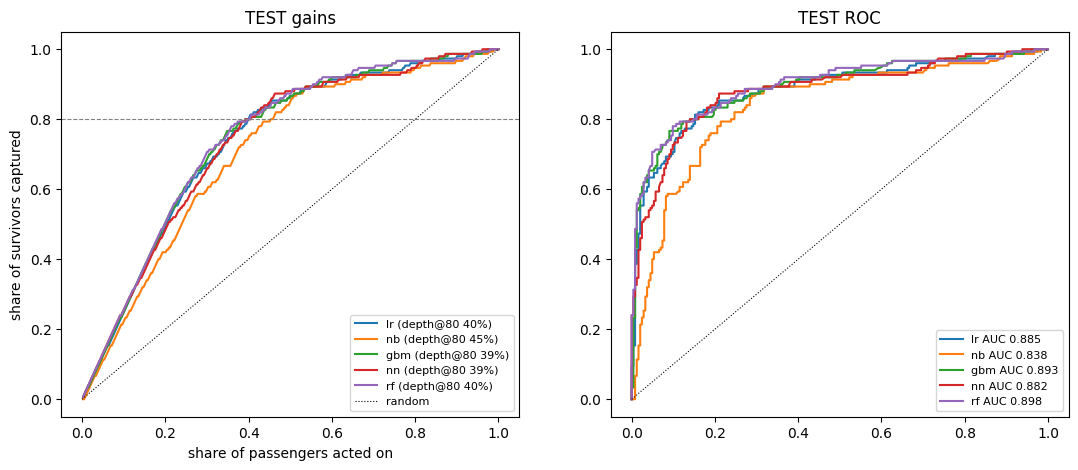


Top 10 predictors per model (top_features):
             lr            nb                gbm                 nn                 rf
0      sex_male      sex_male           sex_male           sex_male           sex_male
1         sibsp    title_Miss           title_Mr                age           title_Mr
2  title_Master     title_Mrs             pclass  ticket_group_size               fare
3     title_Mrs  title_Master           pclass_3       title_Master                age
4           age      pclass_1        cabin_known           pclass_1          title_Mrs
5      pclass_1        deck_E             deck_U           fare_log         title_Miss
6         parch        deck_D              sibsp         embarked_C  ticket_group_size
7    title_Miss        deck_B         title_Rare              sibsp        family_size
8        deck_E         sibsp  ticket_group_size              parch             pclass
9    embarked_C      pclass_2       title_Master           is_alone           pclass_

In [7]:
step_start(5, "BUILD CLASSIFICATION MODELS")
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score
from sklearn.inspection import permutation_importance
try:
    from xgboost import XGBClassifier; XGB = True
except Exception:
    XGB = False

# ---------- metric helpers (written once, reused in every later step) ----------
_TIE = np.random.default_rng(RANDOM_STATE).random(len(modeling_prepared_df))     # fixed random tie-breaker per record
log_seed(5, "score tie-breaking", RANDOM_STATE, "np.random.default_rng(RANDOM_STATE).random(n)", "ties in the score are ordered at random, fixed per record")
_TIE_S = pd.Series(_TIE, index=modeling_prepared_df.index)

def _order(scores, ids=None):
    s = np.asarray(scores, float); tb = _TIE_S.loc[ids].to_numpy() if ids is not None else _TIE[:len(s)]
    return np.lexsort((tb, -s))

def depth_to_capture(scores, y, capture=CAPTURE_TARGET, ids=None):
    """Smallest share of records (ranked by score, descending) that holds `capture` of all positives."""
    y = np.asarray(y)[_order(scores, ids)]; cum = np.cumsum(y) / y.sum()
    return (int(np.searchsorted(cum, capture - 1e-12)) + 1) / len(y)

def capture_at_depth(scores, y, depth, ids=None):
    """Share of all positives found in the top `depth` of the ranked records."""
    y = np.asarray(y)[_order(scores, ids)]; k = int(round(depth * len(y)))
    return y[:k].sum() / y.sum()

def cutoff_at_depth(scores, depth, ids=None):
    s = np.asarray(scores, float)[_order(scores, ids)]; k = max(int(round(depth * len(s))), 1)
    return float(s[k - 1])

def gains_table(scores, y, ids=None):
    y = np.asarray(y)[_order(scores, ids)]; n = len(y)
    return pd.DataFrame({"pct_records": np.arange(1, n + 1) / n, "pct_positives": np.cumsum(y) / y.sum()})

def n_ties_near(scores, depth, window=0.02):
    s = np.sort(np.asarray(scores))[::-1]; n = len(s); lo, hi = int((depth - window) * n), int((depth + window) * n)
    seg = s[max(lo, 0):min(hi, n)]; return int(len(seg) - len(np.unique(seg)))

def decile_table(scores, y, ids=None):
    y = np.asarray(y)[_order(scores, ids)]; s = np.sort(np.asarray(scores))[::-1]; n = len(y)
    dec = (np.arange(n) * 10 // n) + 1
    t = pd.DataFrame({"decile": dec, "y": y, "s": s}).groupby("decile").agg(records=("y", "size"), positives=("y", "sum"), mean_score=("s", "mean"))
    t["rate"] = t.positives / t.records; t["lift"] = t.rate / y.mean(); t["cum_capture"] = t.positives.cumsum() / y.sum()
    return t

def clf_metrics(y, p, ids=None):
    y = np.asarray(y); p = np.asarray(p); yhat = (p > BASE_RATE_TRAIN).astype(int)
    k = int(round(0.3 * len(y))); ys = y[_order(p, ids)]
    return dict(base_rate=y.mean(), roc_auc=roc_auc_score(y, p), pct_correct_at_prior=accuracy_score(y, yhat),
                f1_at_prior=f1_score(y, yhat), precision_at_prior=precision_score(y, yhat, zero_division=0),
                recall_at_prior=recall_score(y, yhat), pct_correct_at_0_5=accuracy_score(y, (p > 0.5).astype(int)),
                lift_decile3=ys[:k].mean() / y.mean(), depth_50=depth_to_capture(p, y, 0.5, ids),
                depth_80=depth_to_capture(p, y, 0.8, ids), depth_95=depth_to_capture(p, y, 0.95, ids))

# ---------- model wrapper: preparation fitted inside fit(), so CV folds refit it too ----------
class PrepModel:
    """Fit = learn preparation on the training rows, encode, fit the estimator. Predict from Step 2 columns."""
    def __init__(self, est, kind): self.est, self.kind = est, kind
    def fit(self, d2, y):
        self.fp = fit_prep(d2); X = encode(apply_prep(d2, self.fp), self.fp, self.kind)
        self.features = list(X.columns); self.est.fit(X, np.asarray(y)); return self
    def predict_proba(self, d2):
        X = encode(apply_prep(d2, self.fp), self.fp, self.kind)[self.features]
        return self.est.predict_proba(X)[:, 1]

def make_estimator(family, params=None):
    params = params or {}
    if family == "lr":  return make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=params.get("C", 1.0)))
    if family == "nb":  return CalibratedClassifierCV(make_pipeline(StandardScaler(), GaussianNB(var_smoothing=params.get("var_smoothing", 1e-9))),
                                                      method="sigmoid", cv=5)
    if family == "nn":  return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=params.get("hidden_layer_sizes", (16,)),
                                             alpha=params.get("alpha", 1e-2), max_iter=3000, random_state=RANDOM_STATE))
    if family == "rf":  return RandomForestClassifier(n_estimators=params.get("n_estimators", 500), min_samples_leaf=params.get("min_samples_leaf", 5),
                                                      max_features=params.get("max_features", "sqrt"), random_state=RANDOM_STATE, n_jobs=4)
    if family == "gbm":
        if XGB: return XGBClassifier(n_estimators=params.get("n_estimators", 200), max_depth=params.get("max_depth", 3),
                                     learning_rate=params.get("learning_rate", 0.05), subsample=0.8, colsample_bytree=0.8,
                                     random_state=RANDOM_STATE, n_jobs=4, eval_metric="logloss")
        return GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE)

FAMILIES = {"lr": ("Logistic Regression", "linear"), "nb": ("Naive Bayes (Gaussian, Platt-calibrated)", "linear"),
            "gbm": ("Gradient Boosting (XGBoost)" if XGB else "Gradient Boosting (sklearn)", "tree"),
            "nn": ("Neural Network (MLP)", "linear"), "rf": ("Random Forest", "tree")}
SKF = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
log_seed(5, "5-fold CV inside TRAIN (out-of-fold predictions)", RANDOM_STATE, "StratifiedKFold(shuffle=True, random_state)")
log_seed(5, "model random_state (RF, GBM, MLP, NB calibration folds)", RANDOM_STATE, "random_state=RANDOM_STATE")

def oof_predict(family, params=None, d2=None, y=None):
    """Out-of-fold probabilities on TRAIN: preparation and model refit inside every fold."""
    d2 = train_df if d2 is None else d2; y = d2[TARGET].to_numpy() if y is None else y
    oof = np.zeros(len(d2))
    for tr, va in SKF.split(d2, y):
        m = PrepModel(make_estimator(family, params), FAMILIES[family][1]).fit(d2.iloc[tr], y[tr])
        oof[va] = m.predict_proba(d2.iloc[va])
    return oof

def train_chosen_point(oof, p_test, y_train, y_test, test_ids):
    """Depth that captures CAPTURE_TARGET on out-of-fold TRAIN, and its probability cutoff, applied to TEST."""
    d = depth_to_capture(oof, y_train, ids=train_df.index); c = cutoff_at_depth(oof, d, ids=train_df.index)
    acted = p_test >= c
    return dict(train_chosen_depth=d, train_chosen_cutoff=c,
                test_capture_depth_rule=capture_at_depth(p_test, y_test, d, ids=test_ids),
                test_pct_acted_cutoff_rule=acted.mean(), test_capture_cutoff_rule=y_test[acted].sum() / y_test.sum(),
                oof_mean_p=float(oof.mean()), test_mean_p=float(p_test.mean()))

for name in ["predictions_train", "predictions_test", "predictions_oof_train"]:
    if name not in globals(): globals()[name] = pd.DataFrame()
if "model_metadata_df" not in globals(): model_metadata_df = pd.DataFrame()

def store_preds(store, ids, actual, model_name, pred, dataset, family):
    g = globals(); new = pd.DataFrame({"RECORD_ID": ids, "actual": actual, "model_name": model_name, "prediction": pred,
                                       "dataset": dataset, "model_family": family})
    old = g[store]
    if len(old) and ((old.model_name == model_name) & (old.dataset == dataset)).any(): return   # never overwrite
    g[store] = pd.concat([old, new], ignore_index=True)

def add_metadata(**row):
    global model_metadata_df
    if len(model_metadata_df) and (model_metadata_df.model_name == row["model_name"]).any(): return
    model_metadata_df = pd.concat([model_metadata_df, pd.DataFrame([row])], ignore_index=True)

y_train, y_test = train_df[TARGET].to_numpy(), test_df[TARGET].to_numpy()
results, op_rows, param_rows, top_features, oof_preds = [], [], [], {}, {}
for fam, (label, kind) in FAMILIES.items():
    if f"model_{fam}" in globals(): print(f"model_{fam} exists: not refit"); continue
    print(f"\n--- {label} ---")
    with timed(f"{fam} fit") as tf: m = PrepModel(make_estimator(fam), kind).fit(train_df, y_train)
    with timed(f"{fam} score") as ts: p_tr, p_te = m.predict_proba(train_df), m.predict_proba(test_df)
    with timed(f"{fam} 5-fold out-of-fold") as tc: oof = oof_predict(fam)
    globals()[f"model_{fam}"] = m; globals()[f"{fam}_features"] = m.features; oof_preds[fam] = oof
    modeling_prepared_df.loc[train_df.index, f"pred_{fam}"] = p_tr; modeling_prepared_df.loc[test_df.index, f"pred_{fam}"] = p_te
    modeling_prepared_df.loc[train_df.index, f"oof_{fam}"] = oof
    store_preds("predictions_train", train_df.index, y_train, fam, p_tr, "TRAIN", label)
    store_preds("predictions_test", test_df.index, y_test, fam, p_te, "TEST", label)
    store_preds("predictions_oof_train", train_df.index, y_train, fam, oof, "OOF", label)
    mtr, mte = clf_metrics(y_train, p_tr, train_df.index), clf_metrics(y_test, p_te, test_df.index)
    op = train_chosen_point(oof, p_te, y_train, y_test, test_df.index)
    results += [dict(model=fam, partition="TRAIN", **mtr), dict(model=fam, partition="TEST", **mte)]
    op_rows.append(dict(model=fam, **op))
    est = m.est
    param_rows.append(dict(model=fam, algorithm=label, params=json.dumps({k: str(v) for k, v in
                      (est.get_params() if not hasattr(est, "steps") else est.steps[-1][1].get_params()).items()
                      if k in ("C", "var_smoothing", "hidden_layer_sizes", "alpha", "n_estimators", "max_depth", "learning_rate",
                               "min_samples_leaf", "max_features", "subsample", "estimator", "method")})))
    # top 10 predictors
    inner = est.steps[-1][1] if hasattr(est, "steps") else est
    if fam in ("rf", "gbm"):
        imp = pd.Series(inner.feature_importances_, index=m.features)
    elif fam == "lr":
        imp = pd.Series(np.abs(inner.coef_[0]), index=m.features)               # standardized inputs -> comparable
    else:
        Xp = encode(apply_prep(train_df, m.fp), m.fp, kind)[m.features]
        pi = permutation_importance(est, Xp, y_train, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
        imp = pd.Series(pi.importances_mean, index=m.features)
    top_features[fam] = imp.sort_values(ascending=False).head(10).index.tolist()
    add_metadata(model_name=f"model_{fam}", model_family=label, target_variable=TARGET, feature_list_name=f"{fam}_features",
                 feature_count=len(m.features), prediction_column_name=f"pred_{fam}", hyperparameters=param_rows[-1]["params"],
                 training_metrics=json.dumps({k: round(v, 4) for k, v in mtr.items()}),
                 testing_metrics=json.dumps({k: round(v, 4) for k, v in mte.items()}),
                 depth_to_capture_80=mte["depth_80"], pct_correct_at_prior=mte["pct_correct_at_prior"],
                 train_chosen_depth=op["train_chosen_depth"], train_chosen_cutoff=op["train_chosen_cutoff"],
                 test_capture_at_train_chosen_depth=op["test_capture_depth_rule"],
                 train_runtime_seconds=tf.seconds, scoring_runtime_seconds=ts.seconds, cv_runtime_seconds=tc.seconds,
                 total_runtime_seconds=tf.seconds + ts.seconds + tc.seconds, notes="")
log_seed(5, "permutation importance (NB, NN top features)", RANDOM_STATE, "permutation_importance(random_state)", "5 repeats on TRAIN")

metrics_df = pd.DataFrame(results)
show(metrics_df.round(3), f"Metrics (threshold for percent correct / F1 / precision / recall = BASE_RATE_TRAIN = {BASE_RATE_TRAIN:.3f}):")
save_table(metrics_df, "metrics")
operating_point_df = pd.DataFrame(op_rows)
show(operating_point_df.round(3), f"Training-chosen operating point (depth that captures {CAPTURE_TARGET:.0%} on out-of-fold TRAIN, applied to TEST):")
save_table(operating_point_df, "train_chosen_operating_point")
print("   depth rule: act on that share of TEST.  cutoff rule: act on TEST records with P >= the out-of-fold cutoff.")
for r in op_rows:
    if abs(r["oof_mean_p"] - r["test_mean_p"]) > 0.05:
        print(f"   {r['model']}: out-of-fold mean P {r['oof_mean_p']:.3f} vs final-model mean P {r['test_mean_p']:.3f}: the cutoff does not carry over; use the depth.")
print("\nCalibration: only Naive Bayes is Platt-calibrated (its raw probabilities pile up near 0 and 1). Calibration does not change the")
print("ranking, so it does not change ROC AUC or the depth metric; it does change who clears the base-rate threshold.")
mean_p = pd.DataFrame({m: [modeling_prepared_df.loc[train_df.index, f"pred_{m}"].mean()] for m in FAMILIES}, index=["mean P on TRAIN"])
show(mean_p.round(3), f"Mean predicted probability (TRAIN base rate {BASE_RATE_TRAIN:.3f}):")
param_df = pd.DataFrame(param_rows); show(param_df, "Parameter report:"); save_table(param_df, "parameters")
for fam in FAMILIES:
    dt = decile_table(modeling_prepared_df.loc[test_df.index, f"pred_{fam}"], y_test, test_df.index); save_table(dt, f"decile_table_{fam}", index=True)
show(decile_table(modeling_prepared_df.loc[test_df.index, "pred_lr"], y_test, test_df.index).round(3), "TEST decile table, logistic regression (others in reports/):")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
from sklearn.metrics import roc_curve
for fam in FAMILIES:
    p = modeling_prepared_df.loc[test_df.index, f"pred_{fam}"].to_numpy(); g = gains_table(p, y_test, test_df.index)
    d80 = depth_to_capture(p, y_test, ids=test_df.index)
    ax[0].plot(g.pct_records, g.pct_positives, label=f"{fam} (depth@80 {d80:.0%})")
    fpr, tpr, _ = roc_curve(y_test, p); ax[1].plot(fpr, tpr, label=f"{fam} AUC {roc_auc_score(y_test, p):.3f}")
ax[0].plot([0, 1], [0, 1], "k:", lw=.8, label="random"); ax[0].axhline(CAPTURE_TARGET, color="grey", ls="--", lw=.8)
ax[0].set_xlabel("share of passengers acted on"); ax[0].set_ylabel("share of survivors captured"); ax[0].set_title("TEST gains"); ax[0].legend(fontsize=8)
ax[1].plot([0, 1], [0, 1], "k:", lw=.8); ax[1].set_title("TEST ROC"); ax[1].legend(fontsize=8)
save_fig(fig, "gains_and_roc")
tf_df = pd.DataFrame(top_features); show(tf_df, "Top 10 predictors per model (top_features):"); save_table(tf_df, "top_features")
model_runtime_summary_df = model_metadata_df[["model_name", "train_runtime_seconds", "scoring_runtime_seconds", "cv_runtime_seconds", "total_runtime_seconds"]]
show(model_runtime_summary_df.round(2), "Runtime:"); save_table(model_runtime_summary_df, "model_runtime")
show_seeds(5)
step_end("model_<fam>, <fam>_features, pred_<fam>, oof_<fam>, predictions_*, model_metadata_df, top_features, metric helpers")

## STEP 6 — CAPACITY EVALUATION

RUNNING STEP 6 — CAPACITY EVALUATION
Start: 2026-11-14 23:35:07

Capacity metrics on TEST (ranked by depth to capture 80%, lower is better):
  model  rank_depth80  depth_50_pct  depth_50_passengers  depth_80_pct  depth_80_passengers  depth_95_pct  depth_95_passengers  capture_at_10pct  capture_at_20pct  capture_at_30pct  capture_at_40pct  capture_at_50pct  ties_near_depth80  roc_auc  pct_correct_at_prior
0   gbm             1         0.198                   78         0.392                  154         0.735                  289             0.247             0.507             0.687             0.800             0.860                  1    0.893                 0.807
1    nn             2         0.206                   81         0.392                  154         0.804                  316             0.253             0.487             0.660             0.800             0.880                  0    0.882                 0.827
2    rf             3         0.198                   78  

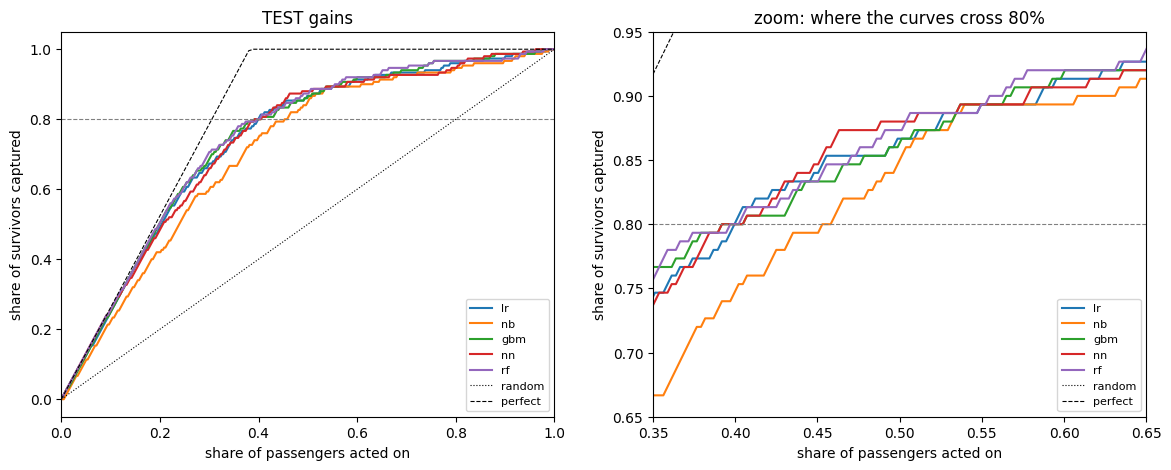

STEP 6 COMPLETE — 0.3 s (0.01 min)
Objects created: capacity_df


In [8]:
step_start(6, "CAPACITY EVALUATION")
rows = []
for fam in FAMILIES:
    p = modeling_prepared_df.loc[test_df.index, f"pred_{fam}"].to_numpy()
    r = dict(model=fam)
    for c in (0.5, 0.8, 0.95):
        d = depth_to_capture(p, y_test, c, test_df.index); r[f"depth_{int(c * 100)}_pct"] = d; r[f"depth_{int(c * 100)}_passengers"] = int(round(d * len(p)))
    for d in (0.1, 0.2, 0.3, 0.4, 0.5): r[f"capture_at_{int(d * 100)}pct"] = capture_at_depth(p, y_test, d, test_df.index)
    r["ties_near_depth80"] = n_ties_near(p, r["depth_80_pct"]); r["roc_auc"] = roc_auc_score(y_test, p)
    r["pct_correct_at_prior"] = accuracy_score(y_test, (p > BASE_RATE_TRAIN).astype(int))
    rows.append(r)
capacity_df = pd.DataFrame(rows).sort_values("depth_80_pct").reset_index(drop=True); capacity_df.insert(1, "rank_depth80", np.arange(1, len(capacity_df) + 1))
show(capacity_df.round(3), f"Capacity metrics on TEST (ranked by depth to capture {CAPTURE_TARGET:.0%}, lower is better):")
save_table(capacity_df, "capacity_metrics")
perfect = CAPTURE_TARGET * y_test.mean()
print(f"\nReference: random ranking needs {CAPTURE_TARGET:.0%} of the file; a perfect ranking needs {CAPTURE_TARGET:.0%} x base rate = {perfect:.1%}.")
best = capacity_df.iloc[0]
print(f"As a decision: to find 80% of survivors with {best.model}, act on the top {best.depth_80_pct:.0%} of passengers: "
      f"{int(best.depth_80_passengers)} of {len(test_df)} TEST passengers, or about {best.depth_80_pct * len(modeling_prepared_df):.0f} of all {len(modeling_prepared_df):,}.")
cmp = capacity_df[["model", "depth_80_pct"]].merge(operating_point_df[["model", "train_chosen_depth", "test_capture_depth_rule"]], on="model")
show(cmp.round(3), "TEST-measured depth vs the depth chosen on TRAIN (what production would use) and what that TRAIN depth captured on TEST:")
save_table(cmp, "test_vs_train_chosen_depth")
print("Depth measured on TEST fairly evaluates the ranking, but it is not an operating point: TEST outcomes are unknown in advance.")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (lo, hi) in zip(ax, [(0, 1), (0.35, 0.65)]):
    for fam in FAMILIES:
        g = gains_table(modeling_prepared_df.loc[test_df.index, f"pred_{fam}"], y_test, test_df.index); a.plot(g.pct_records, g.pct_positives, label=fam)
    xs = np.linspace(0, 1, 101); a.plot(xs, xs, "k:", lw=.8, label="random"); a.plot(xs, np.minimum(xs / y_test.mean(), 1), "k--", lw=.8, label="perfect")
    a.axhline(CAPTURE_TARGET, color="grey", ls="--", lw=.8); a.set_xlim(lo, hi)
    if lo > 0: a.set_ylim(0.65, 0.95)
    a.set_xlabel("share of passengers acted on"); a.set_ylabel("share of survivors captured"); a.legend(fontsize=8)
ax[0].set_title("TEST gains"); ax[1].set_title("zoom: where the curves cross 80%")
save_fig(fig, "gains_zoom")
step_end("capacity_df")

## STEP 7 — FINAL MODEL COMPARISON

RUNNING STEP 7 — FINAL MODEL COMPARISON
Start: 2026-11-14 23:35:07

Comparison on TEST:
       roc_auc  pct_correct_at_prior  pct_correct_at_0_5  lift_decile3  depth_80  train_chosen_depth  test_capture_depth_rule  train_runtime_s  rank_auc  rank_pct_correct_prior  rank_depth80
model                                                                                                                                                                                         
lr       0.885                 0.817               0.824         2.243     0.399               0.469                    0.853            0.028         3                       3             4
nb       0.838                 0.771               0.613         1.998     0.453               0.548                    0.893            0.050         5                       5             5
gbm      0.893                 0.807               0.845         2.287     0.392               0.452                    0.833            0.086      

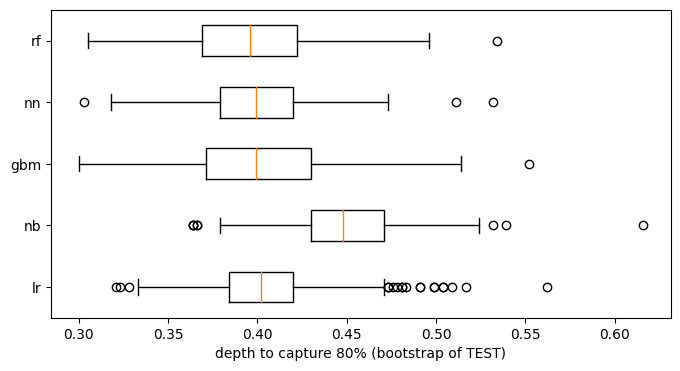


Random seeds used in this step:
  step_number              action_name  seed_value                        function_or_parameter          notes
           7 paired bootstrap of TEST          42 np.random.default_rng(RANDOM_STATE).integers 1000 resamples
STEP 7 COMPLETE — 2.5 s (0.04 min)
Objects created: comp, bootstrap_arms_df, bootstrap_diffs_df, production_model_name, production_depth


In [9]:
step_start(7, "FINAL MODEL COMPARISON")
N_BOOT = 1000
comp = metrics_df[metrics_df.partition == "TEST"].set_index("model")[["roc_auc", "pct_correct_at_prior", "pct_correct_at_0_5", "lift_decile3", "depth_80"]]
comp = comp.join(operating_point_df.set_index("model")[["train_chosen_depth", "test_capture_depth_rule"]])
comp["train_runtime_s"] = model_metadata_df.set_index(model_metadata_df.model_name.str.replace("model_", ""))["train_runtime_seconds"]
comp["rank_auc"] = comp.roc_auc.rank(ascending=False).astype(int)
comp["rank_pct_correct_prior"] = comp.pct_correct_at_prior.rank(ascending=False, method="min").astype(int)
comp["rank_depth80"] = comp.depth_80.rank(method="min").astype(int)
show(comp.round(3), "Comparison on TEST:"); save_table(comp, "comparison", index=True)

# paired bootstrap: every model scored on the same resampled TEST records
P = {fam: modeling_prepared_df.loc[test_df.index, f"pred_{fam}"].to_numpy() for fam in FAMILIES}
tie_test = _TIE_S.loc[test_df.index].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
log_seed(7, "paired bootstrap of TEST", RANDOM_STATE, "np.random.default_rng(RANDOM_STATE).integers", f"{N_BOOT} resamples")
boot = {fam: np.empty(N_BOOT) for fam in FAMILIES}; boot_auc = {fam: np.empty(N_BOOT) for fam in FAMILIES}
with timed("bootstrap"):
    for b in range(N_BOOT):
        idx = rng.integers(0, len(y_test), len(y_test)); yb = y_test[idx]
        for fam in FAMILIES:
            pb = P[fam][idx]; ys = yb[np.lexsort((tie_test[idx], -pb))]
            boot[fam][b] = (np.searchsorted(np.cumsum(ys) / ys.sum(), CAPTURE_TARGET - 1e-12) + 1) / len(ys)
            boot_auc[fam][b] = roc_auc_score(yb, pb)
bootstrap_arms_df = pd.DataFrame([dict(model=f, depth80_test=comp.loc[f, "depth_80"], depth80_lo90=np.percentile(boot[f], 5),
                                      depth80_hi90=np.percentile(boot[f], 95), depth80_sd=boot[f].std(),
                                      auc_lo90=np.percentile(boot_auc[f], 5), auc_hi90=np.percentile(boot_auc[f], 95)) for f in FAMILIES])
show(bootstrap_arms_df.round(3), "Bootstrap 90% intervals:"); save_table(bootstrap_arms_df, "bootstrap_arms")
rows = []
fams = list(FAMILIES)
for i, a in enumerate(fams):
    for b_ in fams[i + 1:]:
        dlt = boot[a] - boot[b_]
        rows.append(dict(model_a=a, model_b=b_, depth80_diff=comp.loc[a, "depth_80"] - comp.loc[b_, "depth_80"],
                         diff_lo90=np.percentile(dlt, 5), diff_hi90=np.percentile(dlt, 95),
                         share_a_better=(dlt < 0).mean(), beyond_noise=bool(np.percentile(dlt, 5) > 0 or np.percentile(dlt, 95) < 0)))
bootstrap_diffs_df = pd.DataFrame(rows); show(bootstrap_diffs_df.round(3), "Paired differences in depth@80 (negative = model_a needs fewer passengers):")
save_table(bootstrap_diffs_df, "bootstrap_diffs")

SIMPLICITY = ["lr", "nb", "rf", "gbm", "nn"]          # simplest first
best_fam = comp.depth_80.idxmin()
tied = [best_fam] + [r.model_b if r.model_a == best_fam else r.model_a for r in bootstrap_diffs_df.itertuples()
                     if best_fam in (r.model_a, r.model_b) and not r.beyond_noise]
production_model_name = sorted(tied, key=SIMPLICITY.index)[0]
production_depth = float(operating_point_df.set_index("model").loc[production_model_name, "train_chosen_depth"])
print(f"\nSmallest TEST depth@80: {best_fam}. Not separable from it by the bootstrap: {sorted(set(tied) - {best_fam}) or 'none'}.")
print(f"Recommended production model (simplest among those): {production_model_name}; act on the top {production_depth:.1%} "
      f"(depth chosen on out-of-fold TRAIN), which captured {comp.loc[production_model_name, 'test_capture_depth_rule']:.1%} of TEST survivors.")
print("\nThresholds: 0.5 says a missed survivor and a false alarm cost the same. The base-rate threshold calls a passenger a survivor")
print("when the model rates them above average, which trades more false alarms for fewer misses. Neither is a business decision;")
print("the capture target is.")
fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([boot[f] for f in fams], labels=fams, vert=False); ax.set_xlabel("depth to capture 80% (bootstrap of TEST)")
save_fig(fig, "bootstrap_depth80")
show_seeds(7)
step_end("comp, bootstrap_arms_df, bootstrap_diffs_df, production_model_name, production_depth")

## STEP 8 — HYPERPARAMETER TUNING (cross-validation inside TRAIN, scored on depth to capture 80%)

In [10]:
step_start(8, "HYPERPARAMETER TUNING")
from itertools import product
GRIDS = {"lr": {"C": [0.01, 0.1, 1.0, 10.0]},
         "nb": {"var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]},
         "nn": {"hidden_layer_sizes": [(8,), (16,), (32,)], "alpha": [1e-3, 1e-2, 1e-1]},
         "rf": {"min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.5]},
         "gbm": {"max_depth": [2, 3, 4], "n_estimators": [100, 300], "learning_rate": [0.03, 0.1]}}
tune_fams = comp.sort_values("depth_80").index[:2].tolist()
print("Tuning the two best families from Step 7:", tune_fams)
tuning_rows, tuning_runtime_rows = [], []
for fam in tune_fams:
    if f"model_{fam}_tuned" in globals(): print(f"model_{fam}_tuned exists: not refit"); continue
    grid = [dict(zip(GRIDS[fam], v)) for v in product(*GRIDS[fam].values())]
    print(f"\n{fam}: {len(grid)} combinations, 5-fold CV inside TRAIN"); t0 = time.time()
    for params in grid:
        oof = oof_predict(fam, params)
        tuning_rows.append(dict(model=fam, params=json.dumps({k: str(v) for k, v in params.items()}),
                                cv_depth80=depth_to_capture(oof, y_train, ids=train_df.index), cv_auc=roc_auc_score(y_train, oof), _params=params, _oof=oof))
    tuning_runtime_rows.append(dict(model=fam, combinations=len(grid), seconds=time.time() - t0))
tuning_df = pd.DataFrame(tuning_rows)
show(tuning_df.drop(columns=["_params", "_oof"]).sort_values(["model", "cv_depth80"]).round(4), "CV results (depth@80 on out-of-fold TRAIN; lower is better):")
save_table(tuning_df.drop(columns=["_params", "_oof"]), "tuning_results")
tuning_runtime_summary_df = pd.DataFrame(tuning_runtime_rows); show(tuning_runtime_summary_df.round(1), "Tuning runtime:")
tuned_rows = []
for fam in tune_fams:
    best_row = tuning_df[tuning_df.model == fam].sort_values(["cv_depth80", "cv_auc"], ascending=[True, False]).iloc[0]
    m = PrepModel(make_estimator(fam, best_row._params), FAMILIES[fam][1]).fit(train_df, y_train)
    p_te = m.predict_proba(test_df); p_tr = m.predict_proba(train_df)
    globals()[f"model_{fam}_tuned"] = m
    modeling_prepared_df.loc[test_df.index, f"pred_{fam}_tuned"] = p_te; modeling_prepared_df.loc[train_df.index, f"pred_{fam}_tuned"] = p_tr
    store_preds("predictions_test", test_df.index, y_test, f"{fam}_tuned", p_te, "TEST", FAMILIES[fam][0] + " (tuned)")
    store_preds("predictions_oof_train", train_df.index, y_train, f"{fam}_tuned", best_row._oof, "OOF", FAMILIES[fam][0] + " (tuned)")
    mte = clf_metrics(y_test, p_te, test_df.index); op = train_chosen_point(best_row._oof, p_te, y_train, y_test, test_df.index)
    gain = comp.loc[fam, "depth_80"] - mte["depth_80"]; noise = float(bootstrap_arms_df.set_index("model").loc[fam, "depth80_sd"])
    tuned_rows.append(dict(model=fam, best_params=best_row.params, cv_depth80=best_row.cv_depth80,
                           untuned_test_depth80=comp.loc[fam, "depth_80"], tuned_test_depth80=mte["depth_80"],
                           untuned_auc=comp.loc[fam, "roc_auc"], tuned_auc=mte["roc_auc"], gain_in_depth=gain, bootstrap_sd=noise,
                           helped=gain > noise, **{k: v for k, v in op.items() if k in ("train_chosen_depth", "test_capture_depth_rule")}))
    add_metadata(model_name=f"model_{fam}_tuned", model_family=FAMILIES[fam][0] + " (tuned)", target_variable=TARGET,
                 feature_list_name=f"{fam}_features", feature_count=len(m.features), prediction_column_name=f"pred_{fam}_tuned",
                 hyperparameters=best_row.params, testing_metrics=json.dumps({k: round(v, 4) for k, v in mte.items()}),
                 depth_to_capture_80=mte["depth_80"], pct_correct_at_prior=mte["pct_correct_at_prior"],
                 train_chosen_depth=op["train_chosen_depth"], train_chosen_cutoff=op["train_chosen_cutoff"],
                 test_capture_at_train_chosen_depth=op["test_capture_depth_rule"], notes="tuned by 5-fold CV inside TRAIN on depth@80")
tuned_compare_df = pd.DataFrame(tuned_rows); show(tuned_compare_df.round(3), "Tuned vs untuned (TEST scored once):")
save_table(tuned_compare_df, "tuned_vs_untuned")
helped = tuned_compare_df[tuned_compare_df.helped]
if len(helped) and helped.tuned_test_depth80.min() < comp.loc[production_model_name, "depth_80"] - float(bootstrap_arms_df.set_index("model").loc[production_model_name, "depth80_sd"]):
    r = helped.sort_values("tuned_test_depth80").iloc[0]
    production_model_name = f"{r.model}_tuned"; production_depth = float(r.train_chosen_depth)
    print(f"\nTuning helped by more than the bootstrap noise: production model is now {production_model_name}.")
else:
    print(f"\nTuning gains are within the bootstrap noise (one SD of depth@80 on TEST). Production model stays {production_model_name}.")
print(f"production_model_name = {production_model_name}, production_depth = {production_depth:.3f}")
print("Unlike the KDD Cup workshop (tuned on TEST for teaching), settings here were chosen by CV inside TRAIN; TEST was used once, to report.")
log_seed(8, "tuning CV folds", RANDOM_STATE, "StratifiedKFold(shuffle=True, random_state) (same folds as Step 5)")
show_seeds(8)
step_end("tuning_df, tuned_compare_df, model_<fam>_tuned, pred_<fam>_tuned, tuning_runtime_summary_df",
         notes=f"{int(tuning_runtime_summary_df.combinations.sum())} combinations in {tuning_runtime_summary_df.seconds.sum():.0f} s")

RUNNING STEP 8 — HYPERPARAMETER TUNING
Start: 2026-11-14 23:35:10
Tuning the two best families from Step 7: ['gbm', 'nn']

gbm: 12 combinations, 5-fold CV inside TRAIN

nn: 9 combinations, 5-fold CV inside TRAIN

CV results (depth@80 on out-of-fold TRAIN; lower is better):
   model                                                              params  cv_depth80  cv_auc
6    gbm  {"max_depth": "3", "n_estimators": "300", "learning_rate": "0.03"}      0.4432  0.8437
10   gbm  {"max_depth": "4", "n_estimators": "300", "learning_rate": "0.03"}      0.4454  0.8437
2    gbm  {"max_depth": "2", "n_estimators": "300", "learning_rate": "0.03"}      0.4465  0.8432
1    gbm   {"max_depth": "2", "n_estimators": "100", "learning_rate": "0.1"}      0.4487  0.8381
3    gbm   {"max_depth": "2", "n_estimators": "300", "learning_rate": "0.1"}      0.4520  0.8392
5    gbm   {"max_depth": "3", "n_estimators": "100", "learning_rate": "0.1"}      0.4531  0.8403
4    gbm  {"max_depth": "3", "n_estimators": "1

## STEP 9 — MEMORY OPTIMIZATION AND OBJECT CLEANUP

In [11]:
step_start(9, "MEMORY OPTIMIZATION AND OBJECT CLEANUP")
import pickle
def obj_mb(o):
    if isinstance(o, pd.DataFrame): return o.memory_usage(deep=True).sum() / 1e6
    try: return len(pickle.dumps(o)) / 1e6
    except Exception: return np.nan
skip = {"In", "Out", "exit", "quit", "get_ipython"}
sizes = sorted(((k, type(v).__name__, obj_mb(v)) for k, v in list(globals().items())
                if not k.startswith("_") and k not in skip and not callable(v) and not isinstance(v, type(sys))), key=lambda t: -(t[2] or 0))
mem_df = pd.DataFrame(sizes[:15], columns=["object", "type", "approx_MB"]); show(mem_df.round(3), "Largest objects:")
save_table(mem_df, "largest_objects")
before = sum(s[2] for s in sizes if s[2] == s[2])
TEMPORARY = ["tuning_rows", "boot", "boot_auc", "P", "dlt", "pb", "yb", "idx", "oof", "Xp", "pi", "m", "g", "rows"]
removed = [k for k in TEMPORARY if k in globals()]
for k in removed: del globals()[k]
if "tuning_df" in globals(): tuning_df = tuning_df.drop(columns=["_oof"], errors="ignore")
gc.collect()
after = sum(obj_mb(v) or 0 for k, v in list(globals().items()) if not k.startswith("_") and k not in skip and not callable(v) and not isinstance(v, type(sys)))
print(f"\nRemoved temporary objects: {removed}")
print(f"Approximate size of notebook objects: {before:.1f} MB before, {after:.1f} MB after.")
print("Kept: modeling_prepared_df, preparation functions, all models, prediction dataframes, feature lists, model_metadata_df, top_features, logs.")
print("On data this size memory is not a problem; the habit matters on large data.")
step_end("(cleanup only)")

RUNNING STEP 9 — MEMORY OPTIMIZATION AND OBJECT CLEANUP
Start: 2026-11-14 23:35:32

Largest objects:
                 object       type  approx_MB
0              model_rf  PrepModel      4.032
1                df_raw  DataFrame      0.657
2                     m  PrepModel      0.026
3               present     Series      0.023
4                     g  DataFrame      0.006
5              by_level  DataFrame      0.003
6             dtypes_df  DataFrame      0.002
7    notebook_timing_df  DataFrame      0.002
8   package_versions_df  DataFrame      0.001
9   notebook_timing_log       list      0.001
10                 rows       list      0.001
11      random_seed_log       list      0.001
12                nuniq  DataFrame      0.001
13            num_stats  DataFrame      0.001
14            miss_rate  DataFrame      0.001

Removed temporary objects: ['tuning_rows', 'boot', 'boot_auc', 'P', 'dlt', 'pb', 'yb', 'idx', 'oof', 'Xp', 'pi', 'm', 'g', 'rows']
Approximate size of notebook ob

## STEP 10 — INPUT SHUFFLING VARIABLE IMPORTANCE

RUNNING STEP 10 — INPUT SHUFFLING VARIABLE IMPORTANCE
Start: 2026-11-14 23:35:32
   [one scoring pass] 0.01 s
   estimated shuffling time: 4 s
Regenerated vs stored production score: max |diff| = 0.00e+00
   [input shuffling (all variables)] 2.14 s

Production model: lr; analysis set: 393 TEST passengers; top group = top 47% (184 passengers).
Baseline: {'depth_to_capture_80': 0.399, 'roc_auc': 0.885, 'capture_at_production_depth': 0.853}

Overall importance (ranked by mean_record_iqr):
               model            feature  rank     ranking_stat  ranking_value  mean_record_variance  median_record_variance  mean_record_std  median_record_std  mean_record_iqr  median_record_iqr  mean_record_mad  median_record_mad  mean_abs_delta  median_abs_delta  p90_abs_delta  fraction_abs_delta_gt_eps  n_rows  n_shuffles   eps  overall_rank
0   production_score                sex     1  mean_record_iqr         0.3182                0.0273                  0.0292           0.1595             0.1709  

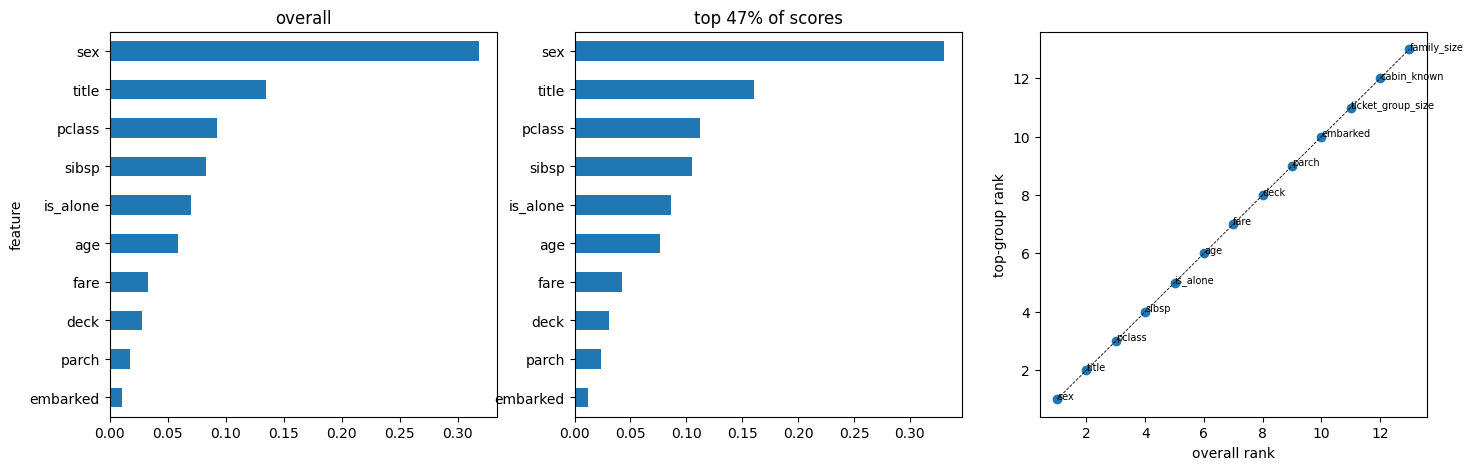


Inputs the production model does not use (importance 0 by construction): ['cabin_known', 'family_size']  (linear models drop them as overlapping encodings, Step 4)

Discussion:
                        topic                                                                                                                                                    note
0             top-group shift                                                                           Variables gaining the most rank in the top group: ['sex', 'title', 'pclass'].
1  instability vs degradation                    A variable can move many scores a little (high IQR) yet barely change who is in the top group (small depth change), and the reverse.
2          overlapping inputs       sex and title carry overlapping information (Mr = male adult): shuffling one leaves the other intact, so each looks less important than the pair.
3            vs other methods  Input shuffling needs no target and measures score movement per

In [12]:
step_start(10, "INPUT SHUFFLING VARIABLE IMPORTANCE")
N_SHUFFLES = 50
TOP_GROUP_FRACTION = production_depth
production_model = globals()[f"model_{production_model_name}"]
shuffle_feature_list = list(INPUTS)          # Step 2 columns; derived features (family_size, deck, ...) are inputs of their own
def production_scorer(X):
    """P(survived) of the production model from Step 2 columns; reapplies the TRAIN-fitted preparation."""
    return production_model.predict_proba(X)
shuffle_analysis_df = test_df
X_base = shuffle_analysis_df[shuffle_feature_list].reset_index(drop=True)
with timed("one scoring pass") as t1: baseline_scores = production_scorer(X_base)
print(f"   estimated shuffling time: {t1.seconds * len(shuffle_feature_list) * N_SHUFFLES:.0f} s")
stored = modeling_prepared_df.loc[shuffle_analysis_df.index, f"pred_{production_model_name}"].to_numpy()
print(f"Regenerated vs stored production score: max |diff| = {np.max(np.abs(baseline_scores - stored)):.2e}")
production_score_test = pd.Series(baseline_scores, index=shuffle_analysis_df.index, name="production_score")
yA = shuffle_analysis_df[TARGET].to_numpy(); idsA = shuffle_analysis_df.index
metric_fns = {"depth_to_capture_80": lambda s: depth_to_capture(s, yA, ids=idsA),
              "roc_auc": lambda s: roc_auc_score(yA, s),
              "capture_at_production_depth": lambda s: capture_at_depth(s, yA, production_depth, ids=idsA)}
base_metrics = {k: f(baseline_scores) for k, f in metric_fns.items()}
log_seed(10, "input shuffling permutations", RANDOM_STATE, "seeded per (seed, feature index, shuffle index)", f"{N_SHUFFLES} shuffles per variable")
try:
    sys.path.insert(0, str(INPUT_SHUFFLING_SRC))
    from input_shuffling_v2.in_shuff_engine import run_engine
    from input_shuffling_v2.in_shuff_importance import build_feature_summary, record_stat_matrix
    USE_FRAMEWORK = True
except Exception as e:
    print("input_shuffling_v2 not importable, using notebook-native shuffling:", e); USE_FRAMEWORK = False
with timed("input shuffling (all variables)") as tsh:
    if USE_FRAMEWORK:
        cfg = {"run": {"seed": RANDOM_STATE}, "shuffling": {"n_shuffles": N_SHUFFLES}, "importance": {"eps": 0.01, "ranking_stat": "mean_record_iqr"},
               "performance": {"shuffle_batch": 10, "n_jobs": 1}, "schema": {"prediction_columns": ["production_score"]}}
        shuffle_results = run_engine(X_base, [(f, i) for i, f in enumerate(shuffle_feature_list)], production_scorer, baseline_scores, cfg, metric_fns=metric_fns)
        overall_importance_df = build_feature_summary(shuffle_results, cfg)
        record_iqr_df = record_stat_matrix(shuffle_results, "iqr")
        deg = {r.feature: (pd.DataFrame(r.metric_values) if not isinstance(r.metric_values, pd.DataFrame) else r.metric_values) for r in shuffle_results}
    else:
        iqr_cols, deg, rows_ = {}, {}, []
        for j, f in enumerate(shuffle_feature_list):
            S = np.empty((N_SHUFFLES, len(X_base))); mv = []
            for m_ in range(N_SHUFFLES):
                Xs = X_base.copy(); Xs[f] = np.random.default_rng([RANDOM_STATE, j, m_]).permutation(Xs[f].to_numpy())
                S[m_] = production_scorer(Xs); mv.append({k: fn(S[m_]) for k, fn in metric_fns.items()})
            q75, q25 = np.percentile(S, [75, 25], axis=0); iqr_cols[f] = q75 - q25; deg[f] = pd.DataFrame(mv)
            d_ = S - baseline_scores
            rows_.append(dict(feature=f, mean_record_iqr=iqr_cols[f].mean(), median_record_iqr=np.median(iqr_cols[f]),
                              mean_record_std=S.std(axis=0, ddof=1).mean(), mean_abs_delta=np.abs(d_).mean(),
                              fraction_abs_delta_gt_eps=(np.abs(d_) > 0.01).mean(), n_records=len(X_base), n_shuffles=N_SHUFFLES))
        overall_importance_df = pd.DataFrame(rows_); record_iqr_df = pd.DataFrame(iqr_cols)
overall_importance_df = overall_importance_df.sort_values("mean_record_iqr", ascending=False).reset_index(drop=True)
overall_importance_df["overall_rank"] = np.arange(1, len(overall_importance_df) + 1)
top_mask = baseline_scores >= cutoff_at_depth(baseline_scores, TOP_GROUP_FRACTION)
top_group_importance_df = record_iqr_df[top_mask].mean().rename("mean_record_iqr").to_frame()
top_group_importance_df["median_record_iqr"] = record_iqr_df[top_mask].median()
top_group_importance_df = top_group_importance_df.sort_values("mean_record_iqr", ascending=False)
top_group_importance_df["top_group_rank"] = np.arange(1, len(top_group_importance_df) + 1)
top_group_importance_df["records_used"] = int(top_mask.sum())
importance_rank_shift_df = overall_importance_df.set_index("feature")[["overall_rank", "mean_record_iqr"]].join(
    top_group_importance_df[["top_group_rank", "mean_record_iqr"]], rsuffix="_top")
importance_rank_shift_df["rank_shift"] = importance_rank_shift_df.overall_rank - importance_rank_shift_df.top_group_rank
importance_rank_shift_df["iqr_change"] = importance_rank_shift_df.mean_record_iqr_top - importance_rank_shift_df.mean_record_iqr
capacity_degradation_df = pd.DataFrame([{"feature": f, **{f"{k}_degradation": (float(np.mean(mv[k])) - base_metrics[k]) * (1 if k == "depth_to_capture_80" else -1)
                                                          for k in metric_fns}} for f, mv in deg.items()]).set_index("feature")
capacity_degradation_df = capacity_degradation_df.join(importance_rank_shift_df[["overall_rank", "top_group_rank", "mean_record_iqr"]]).sort_values("overall_rank")
print(f"\nProduction model: {production_model_name}; analysis set: {len(X_base)} TEST passengers; top group = top {TOP_GROUP_FRACTION:.0%} ({int(top_mask.sum())} passengers).")
print("Baseline:", {k: round(v, 3) for k, v in base_metrics.items()})
show(overall_importance_df.round(4), "Overall importance (ranked by mean_record_iqr):")
show(top_group_importance_df.round(4), f"Top-group importance (top {TOP_GROUP_FRACTION:.0%} of scores):")
show(importance_rank_shift_df.sort_values("rank_shift", ascending=False).round(4), "Rank shift (positive = more important in the top group):")
show(capacity_degradation_df.round(3), "Capacity degradation (positive = worse: more depth needed, lower AUC, lower capture):")
save_table(overall_importance_df, "overall_importance"); save_table(top_group_importance_df, "top_group_importance", index=True)
save_table(importance_rank_shift_df, "rank_shift", index=True); save_table(capacity_degradation_df, "capacity_degradation", index=True)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
overall_importance_df.head(10).plot.barh(x="feature", y="mean_record_iqr", ax=ax[0], legend=False); ax[0].invert_yaxis(); ax[0].set_title("overall")
top_group_importance_df.head(10).mean_record_iqr.plot.barh(ax=ax[1]); ax[1].invert_yaxis(); ax[1].set_title(f"top {TOP_GROUP_FRACTION:.0%} of scores")
u = importance_rank_shift_df
ax[2].scatter(u.overall_rank, u.top_group_rank)
for f, rr in u.iterrows(): ax[2].annotate(f, (rr.overall_rank, rr.top_group_rank), fontsize=7)
ax[2].plot([1, len(u)], [1, len(u)], "k--", lw=.6); ax[2].set_xlabel("overall rank"); ax[2].set_ylabel("top-group rank")
save_fig(fig, "input_shuffling_importance")
unused = [f for f in shuffle_feature_list if f not in production_model.features and not any(c.startswith(f + "_") for c in production_model.features)]
if unused: print(f"\nInputs the production model does not use (importance 0 by construction): {unused}"
                 + ("  (linear models drop them as overlapping encodings, Step 4)" if production_model.kind == "linear" else ""))
movers = importance_rank_shift_df.sort_values("rank_shift", ascending=False).head(3).index.tolist()
input_shuffling_discussion_df = pd.DataFrame({"topic": ["top-group shift", "instability vs degradation", "overlapping inputs", "vs other methods"], "note": [
    f"Variables gaining the most rank in the top group: {movers}.",
    "A variable can move many scores a little (high IQR) yet barely change who is in the top group (small depth change), and the reverse.",
    "sex and title carry overlapping information (Mr = male adult): shuffling one leaves the other intact, so each looks less important than the pair.",
    "Input shuffling needs no target and measures score movement per record; permutation importance measures a metric drop; SHAP splits a score additively."]})
show(input_shuffling_discussion_df, "Discussion:"); save_table(input_shuffling_discussion_df, "discussion")
show_seeds(10)
step_end("production_scorer, production_score_test, overall/top_group importance, capacity_degradation_df",
         notes=f"input shuffling {tsh.seconds:.0f} s ({'framework' if USE_FRAMEWORK else 'notebook-native'})")

## STEP 11 — RESPONSE PROFILES FOR TOP VARIABLES

RUNNING STEP 11 — RESPONSE PROFILES FOR TOP VARIABLES
Start: 2026-11-14 23:35:35
Variables profiled: ['sex', 'title', 'pclass']


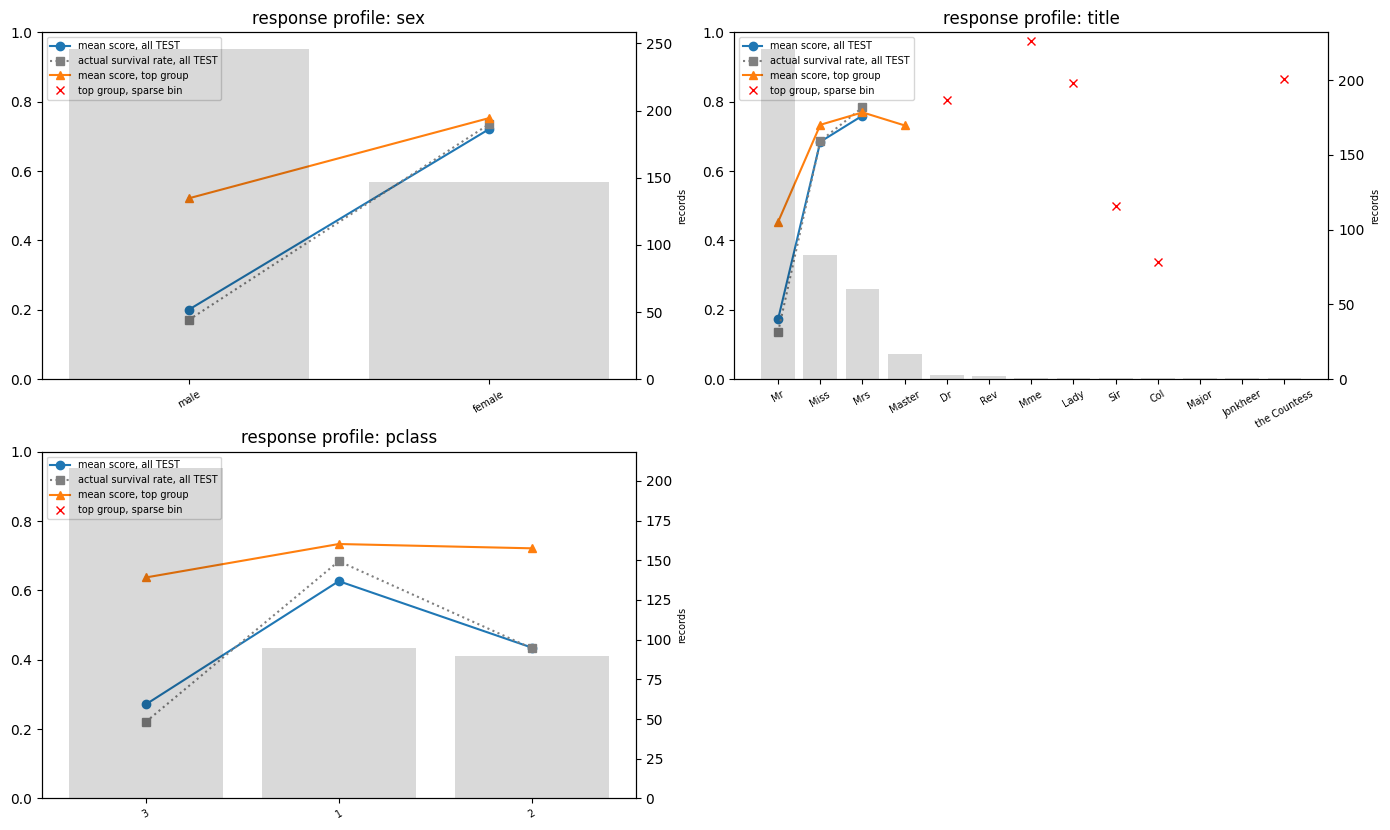


Sparse bins (not connected in the plots):
  variable           bin  records  records_top
0    title        Master       17           11
1    title            Dr        3            1
2    title           Rev        2            0
3    title           Mme        1            1
4    title          Lady        1            1
5    title           Sir        1            1
6    title           Col        1            1
7    title         Major        1            0
8    title      Jonkheer        1            0
9    title  the Countess        1            1

sex:
    label  records  mean_score  survival_rate  records_top  mean_score_top
0    male      246        0.20          0.171           44           0.521
1  female      147        0.72          0.735          140           0.753

title:
           label  records  mean_score  survival_rate  records_top  mean_score_top
0             Mr      221       0.173          0.136           31           0.453
1           Miss       83       0.684

In [13]:
step_start(11, "RESPONSE PROFILES FOR TOP VARIABLES")
MIN_BIN_RECORDS_OVERALL, MIN_BIN_RECORDS_TOP_GROUP, N_BINS = 20, 10, 5
response_profile_variables = list(dict.fromkeys(overall_importance_df.feature.head(3).tolist() + top_group_importance_df.index[:3].tolist()))
print("Variables profiled:", response_profile_variables)
prof_src = test_df.copy(); prof_src["score"] = production_score_test; prof_src["top_group"] = top_mask
response_profile_bin_edges, response_profile_plot_dataframes, sparse_rows = {}, {}, []
n = len(response_profile_variables); fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(14, 4.2 * ((n + 1) // 2))); axes = np.atleast_1d(axes).ravel()
for ax, v in zip(axes, response_profile_variables):
    x = prof_src[v]
    if pd.api.types.is_numeric_dtype(x) and x.nunique() > 10:
        _, edges = pd.qcut(x, N_BINS, retbins=True, duplicates="drop"); edges[0] -= 1e-9; response_profile_bin_edges[v] = edges
        b = pd.cut(x, edges, include_lowest=True)
        bins = pd.DataFrame({"bin": b}); bins["bin_order"] = b.cat.codes
        bins["bin_midpoint"] = b.apply(lambda iv: iv.mid if pd.notna(iv) else np.nan).astype(float)
        bins["label"] = b.astype(str).where(b.notna(), "missing")
    else:
        lv = x.astype(str).value_counts().index.tolist(); response_profile_bin_edges[v] = lv
        bins = pd.DataFrame({"label": x.astype(str)}); bins["bin_order"] = bins.label.map({l: i for i, l in enumerate(lv)}); bins["bin_midpoint"] = np.nan
    t = prof_src[["score", TARGET, "top_group"]].join(bins)
    over = t.groupby(["bin_order", "label"], observed=True).agg(records=("score", "size"), mean_score=("score", "mean"), survival_rate=(TARGET, "mean"))
    top = t[t.top_group].groupby(["bin_order", "label"], observed=True).agg(records_top=("score", "size"), mean_score_top=("score", "mean"))
    pdf = over.join(top).reset_index().sort_values("bin_order"); pdf["records_top"] = pdf.records_top.fillna(0).astype(int)
    pdf["sparse_overall"] = pdf.records < MIN_BIN_RECORDS_OVERALL; pdf["sparse_top"] = pdf.records_top < MIN_BIN_RECORDS_TOP_GROUP
    response_profile_plot_dataframes[v] = pdf; save_table(pdf, f"profile_{v}")
    for r in pdf[pdf.sparse_overall | pdf.sparse_top].itertuples():
        sparse_rows.append(dict(variable=v, bin=r.label, records=r.records, records_top=r.records_top))
    xs = np.arange(len(pdf))
    ax.plot(xs, pdf.mean_score.where(~pdf.sparse_overall), "o-", label="mean score, all TEST")
    ax.plot(xs, pdf.survival_rate.where(~pdf.sparse_overall), "s:", color="grey", label="actual survival rate, all TEST")
    ax.plot(xs, pdf.mean_score_top.where(~pdf.sparse_top), "^-", label="mean score, top group")
    ax.plot(xs[pdf.sparse_top], pdf.mean_score_top[pdf.sparse_top], "x", color="red", label="top group, sparse bin")
    ax.set_xticks(xs); ax.set_xticklabels(pdf.label, rotation=30, fontsize=7); ax.set_ylim(0, 1); ax.set_title(f"response profile: {v}")
    a2 = ax.twinx(); a2.bar(xs, pdf.records, alpha=.15, color="k"); a2.set_ylabel("records", fontsize=7)
    ax.legend(fontsize=7, loc="upper left")
for ax in axes[n:]: ax.axis("off")
fig.tight_layout(); save_fig(fig, "response_profiles")
response_profile_sparse_bins_df = pd.DataFrame(sparse_rows); show(response_profile_sparse_bins_df, "Sparse bins (not connected in the plots):")
save_table(response_profile_sparse_bins_df, "sparse_bins")
for v, pdf in response_profile_plot_dataframes.items():
    show(pdf[["label", "records", "mean_score", "survival_rate", "records_top", "mean_score_top"]].round(3), f"{v}:")
gap = {v: float((p.mean_score - p.survival_rate).abs().max()) for v, p in response_profile_plot_dataframes.items()}
response_profile_discussion_df = pd.DataFrame({"topic": ["shape", "score vs actual", "top group", "sparse bins"], "note": [
    "Read each panel left to right: direction and thresholds (e.g. children vs adults in age, class steps, female vs male).",
    "Largest gap between mean score and actual survival rate per variable: " + ", ".join(f"{k} {v:.2f}" for k, v in gap.items()) + ". With ~40-80 passengers per bin, gaps of 0.1 are within noise.",
    "The top group is mostly female and upper class, so within it the remaining variables separate a narrower population.",
    f"{len(response_profile_sparse_bins_df)} sparse bins; conclusions there rest on very few passengers."]})
show(response_profile_discussion_df, "Discussion:"); save_table(response_profile_discussion_df, "discussion")
step_end("response_profile_variables, response_profile_bin_edges, response_profile_plot_dataframes, response_profile_sparse_bins_df")

## STEP 12 — SUPERVISED ASSOCIATION RULE DISCOVERY (mine on TRAIN, check on TEST)

RUNNING STEP 12 — SUPERVISED ASSOCIATION RULE DISCOVERY
Start: 2026-11-14 23:35:35
Antecedent items: 49 built, 45 kept (TRAIN support between 0.02 and 0.95).
Outcome base rates (TRAIN): {'CONS::SURVIVED': 0.382, 'CONS::DIED': 0.618}
   [matrix rule counting] 0.01 s
   1,050 rules counted (support and outcome-count floors applied).

SURVIVED: 112 two-item rules kept (91 confirmed on TEST), 26 one-item rules.

Top 20 two-item rules -> SURVIVED (TRAIN lift, then records):
                          antecedent  records  support  records_with_outcome  confidence   lift  best_parent_lift  test_records  test_confidence  test_lift  confirmed_on_test  share_of_train_positives
26               sex=female & deck=B       22    0.024                    22       1.000  2.617             1.895          14.0            1.000      2.620               True                     0.063
53              title=Mrs & pclass=1       53    0.058                    52       0.981  2.568             2.063          2

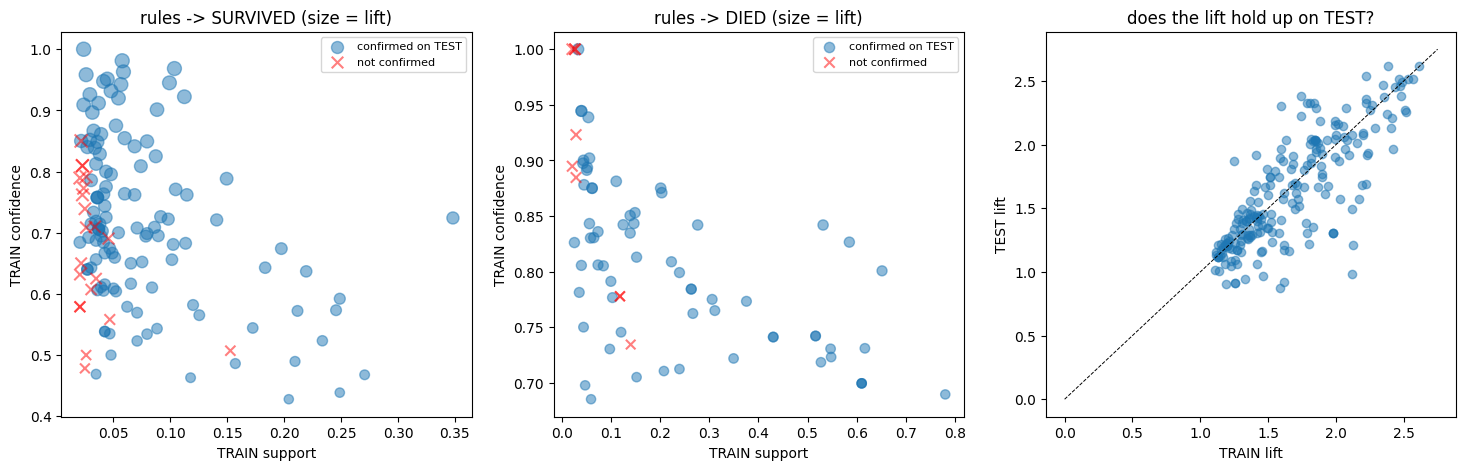


Variables in the top 20 two-item SURVIVED rules vs input shuffling rank:
                   in_top20_survived_rules  overall_rank
sex                                    8.0             1
title                                 12.0             2
pclass                                 4.0             3
sibsp                                  NaN             4
is_alone                               NaN             5
age                                    NaN             6
fare                                   3.0             7
deck                                   2.0             8
parch                                  1.0             9
embarked                               3.0            10
ticket_group_size                      4.0            11
cabin_known                            3.0            12
family_size                            NaN            13

TRAIN lift -> TEST lift for two-item rules: median 1.68 -> 1.62; 83% confirmed. The drop is the cost of searching 1,050 rules o

In [14]:
step_start(12, "SUPERVISED ASSOCIATION RULE DISCOVERY")
MIN_ANTECEDENT_SUPPORT, MIN_OUTCOME_RECORDS, MIN_LIFT, BEAT_PARENT = 0.02, 10, 1.10, 1.05
ar_train_df = apply_prep(train_df, prep_train); ar_test_df = apply_prep(test_df, prep_train)     # original units, Step 4 imputation + grouping
ar_train_df[TARGET] = y_train; ar_test_df[TARGET] = y_test
SMALL_INT_GROUPS = {"sibsp": [0, 1, 2], "parch": [0, 1, 2], "family_size": [1, 2, 3, 4], "ticket_group_size": [1, 2, 3, 4]}
ar_bin_edges = {}
def to_items(c, fit=False):
    """Antecedent items as 0/1 columns named ANT::variable=value; bins learned on TRAIN only."""
    it = {}
    for v in ["sex", "title", "deck", "embarked", "pclass"]:
        for l in sorted(ar_train_df[v].astype(str).unique()): it[f"ANT::{v}={l}"] = (c[v].astype(str) == l)
    for v, top in SMALL_INT_GROUPS.items():
        for l in top: it[f"ANT::{v}={l}"] = (c[v] == l)
        it[f"ANT::{v}>={top[-1] + 1}"] = (c[v] > top[-1])
    for v in ["age", "fare"]:
        if fit: _, e = pd.qcut(ar_train_df[v], 4, retbins=True, duplicates="drop"); e[0], e[-1] = -np.inf, np.inf; ar_bin_edges[v] = e
        b = pd.cut(c[v], ar_bin_edges[v])
        for iv in b.cat.categories: it[f"ANT::{v} in ({iv.left:.1f}, {iv.right:.1f}]"] = (b == iv)
    for v in ["is_alone", "cabin_known", "age_missing"]: it[f"ANT::{v}=1"] = (c[v] == 1)
    X = pd.DataFrame(it).astype(np.int8)
    X["CONS::SURVIVED"] = (c[TARGET] == 1).astype(np.int8); X["CONS::DIED"] = (c[TARGET] == 0).astype(np.int8)
    return X
transaction_matrix_train = to_items(ar_train_df, fit=True); transaction_matrix_test = to_items(ar_test_df)
ant_all = [c for c in transaction_matrix_train if c.startswith("ANT::")]
sup = transaction_matrix_train[ant_all].mean()
ant_cols = sup[(sup >= MIN_ANTECEDENT_SUPPORT) & (sup <= 0.95)].index.tolist()
print(f"Antecedent items: {len(ant_all)} built, {len(ant_cols)} kept (TRAIN support between {MIN_ANTECEDENT_SUPPORT} and 0.95).")
outcome_cols = ["CONS::SURVIVED", "CONS::DIED"]
print("Outcome base rates (TRAIN):", transaction_matrix_train[outcome_cols].mean().round(3).to_dict())
src_var = np.array([c[5:].split("=")[0].split(" in ")[0].split(">=")[0] for c in ant_cols])
with timed("matrix rule counting") as tr_:
    X = transaction_matrix_train[ant_cols].to_numpy(np.float32); n_rows = len(X)
    n_A = X.sum(0); n_AB = X.T @ X
    rules = []
    for oc in outcome_cols:
        c = transaction_matrix_train[oc].to_numpy(np.float32); rate = c.mean()
        n_AC = X.T @ c; n_ABC = X.T @ (X * c[:, None])
        single_lift = {}
        for i in range(len(ant_cols)):
            if n_A[i] / n_rows >= MIN_ANTECEDENT_SUPPORT and n_AC[i] >= MIN_OUTCOME_RECORDS:
                lift = n_AC[i] / n_A[i] / rate; single_lift[i] = lift
                rules.append(dict(outcome=oc[6:], antecedent=ant_cols[i][5:], n_items=1, records=int(n_A[i]), support=n_A[i] / n_rows,
                                  records_with_outcome=int(n_AC[i]), confidence=n_AC[i] / n_A[i], lift=lift, _ix=(i,)))
            else:
                single_lift[i] = n_AC[i] / max(n_A[i], 1) / rate
        I, J = np.triu_indices(len(ant_cols), 1)
        keep = (src_var[I] != src_var[J]) & (n_AB[I, J] / n_rows >= MIN_ANTECEDENT_SUPPORT) & (n_ABC[I, J] >= MIN_OUTCOME_RECORDS)
        for i, j in zip(I[keep], J[keep]):
            lift = n_ABC[i, j] / n_AB[i, j] / rate
            rules.append(dict(outcome=oc[6:], antecedent=f"{ant_cols[i][5:]} & {ant_cols[j][5:]}", n_items=2, records=int(n_AB[i, j]),
                              support=n_AB[i, j] / n_rows, records_with_outcome=int(n_ABC[i, j]), confidence=n_ABC[i, j] / n_AB[i, j],
                              lift=lift, best_parent_lift=max(single_lift[i], single_lift[j]), _ix=(i, j)))
supervised_rules_all = pd.DataFrame(rules)
print(f"   {len(supervised_rules_all):,} rules counted (support and outcome-count floors applied).")
association_rule_runtime_df = pd.DataFrame([dict(operation="matrix rule counting", seconds=tr_.seconds, rules=len(supervised_rules_all))])
r = supervised_rules_all[supervised_rules_all.lift >= MIN_LIFT].copy()
r = r[(r.n_items == 1) | (r.lift >= BEAT_PARENT * r.best_parent_lift)]
# TEST check
Xt = transaction_matrix_test[ant_cols].to_numpy(bool)
def test_check(row):
    m = Xt[:, list(row._ix)].all(axis=1); oc = transaction_matrix_test[f"CONS::{row.outcome}"].to_numpy()
    n = int(m.sum()); conf = oc[m].mean() if n else np.nan
    return pd.Series(dict(test_records=n, test_confidence=conf, test_lift=conf / oc.mean() if n else np.nan))
r = pd.concat([r.reset_index(drop=True), r.apply(test_check, axis=1).reset_index(drop=True)], axis=1)
r["confirmed_on_test"] = (r.test_lift >= 1.0) & (r.test_records >= 10)
pos_train = int(y_train.sum())
r["share_of_train_positives"] = np.where(r.outcome == "SURVIVED", r.records_with_outcome / pos_train, np.nan)
cols = ["antecedent", "records", "support", "records_with_outcome", "confidence", "lift", "best_parent_lift",
        "test_records", "test_confidence", "test_lift", "confirmed_on_test", "share_of_train_positives"]
association_rules_survived = r[r.outcome == "SURVIVED"].sort_values(["lift", "records"], ascending=False)
association_rules_died = r[r.outcome == "DIED"].sort_values(["lift", "records"], ascending=False)
for name, rs in [("survived", association_rules_survived), ("died", association_rules_died)]:
    two = rs[rs.n_items == 2]; one = rs[rs.n_items == 1]
    print(f"\n{name.upper()}: {len(two)} two-item rules kept ({int(two.confirmed_on_test.sum())} confirmed on TEST), {len(one)} one-item rules.")
    show(two[cols].head(20).round(3), f"Top 20 two-item rules -> {name.upper()} (TRAIN lift, then records):")
    show(one[[c for c in cols if c != "best_parent_lift"]].head(15).round(3), f"One-item reference rules -> {name.upper()}:")
    save_table(rs.drop(columns=["_ix"]), f"rules_{name}")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, rs) in zip(ax[:2], [("SURVIVED", association_rules_survived), ("DIED", association_rules_died)]):
    ok = rs.confirmed_on_test
    a.scatter(rs.support[ok], rs.confidence[ok], s=40 * rs.lift[ok], alpha=.5, label="confirmed on TEST")
    a.scatter(rs.support[~ok], rs.confidence[~ok], s=40 * rs.lift[~ok], alpha=.5, marker="x", color="red", label="not confirmed")
    a.set_xlabel("TRAIN support"); a.set_ylabel("TRAIN confidence"); a.set_title(f"rules -> {name} (size = lift)"); a.legend(fontsize=8)
ax[2].scatter(r.lift, r.test_lift, alpha=.5); lim = [0, max(r.lift.max(), r.test_lift.max()) * 1.05]
ax[2].plot(lim, lim, "k--", lw=.7); ax[2].set_xlabel("TRAIN lift"); ax[2].set_ylabel("TEST lift"); ax[2].set_title("does the lift hold up on TEST?")
save_fig(fig, "rules")
# comparison with model results
def base_var(a): return {s.split("=")[0].split(" in ")[0].split(">=")[0] for s in a.split(" & ")}
rule_vars = pd.Series([v for a in association_rules_survived[association_rules_survived.n_items == 2].antecedent.head(20) for v in base_var(a)]).value_counts()
cmpv = pd.DataFrame({"in_top20_survived_rules": rule_vars}).join(overall_importance_df.set_index("feature")[["overall_rank"]], how="outer")
show(cmpv.sort_values("overall_rank"), "Variables in the top 20 two-item SURVIVED rules vs input shuffling rank:"); save_table(cmpv, "rules_vs_importance", index=True)
conf = r[r.n_items == 2]
print(f"\nTRAIN lift -> TEST lift for two-item rules: median {conf.lift.median():.2f} -> {conf.test_lift.median():.2f}; "
      f"{conf.confirmed_on_test.mean():.0%} confirmed. The drop is the cost of searching {len(supervised_rules_all):,} rules on {len(X)} passengers.")
print("Interactions such as sex x class are what a main-effects logistic regression cannot represent without an explicit interaction term.")
show(association_rule_runtime_df.round(3), "Runtime:"); save_table(association_rule_runtime_df, "runtime")
step_end("ar_train_df, ar_test_df, ar_bin_edges, transaction_matrix_train/test, supervised_rules_all, association_rules_survived/died",
         notes=f"rule counting {tr_.seconds:.2f} s")

## FINAL NOTEBOOK TIMING REPORT

RUNNING STEP 13 — FINAL NOTEBOOK TIMING REPORT
Start: 2026-11-14 23:35:36

Step runtimes:
    step_number                                             step_name  elapsed_seconds  elapsed_minutes                                     major_runtime_notes
0             0                                     ENVIRONMENT SETUP             1.00            0.017  setup only: no audit, no RECORD_ID, no columns dropped
1             1                                   LOAD DATA AND AUDIT             0.03            0.000                                                        
2             2  NON-LEARNED DATA PREPARATION AND FEATURE ENGINEERING             0.02            0.000                                                        
3             3                                TRAIN / HOLD-OUT SPLIT             0.00            0.000                                                        
4             4            FITTED PREPARATION (LEARNED ON TRAIN ONLY)             0.10            0.002       

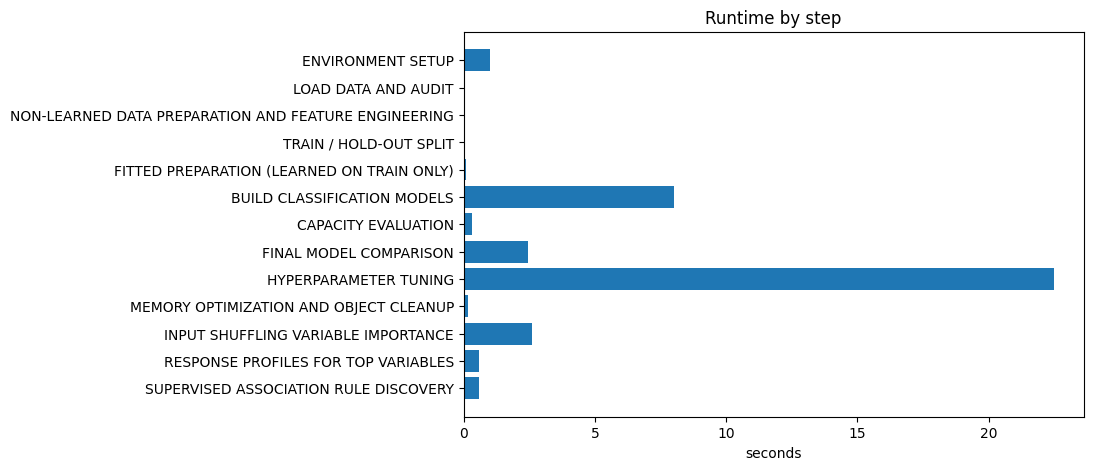


Saved model_metadata, timing, seeds, and TEST predictions for 7 models to reports/
STEP 13 COMPLETE — 0.2 s (0.00 min)
Objects created: notebook_timing_df, model_runtime_summary_df, random_seed_df


In [15]:
step_start(13, "FINAL NOTEBOOK TIMING REPORT")
notebook_timing_df = pd.DataFrame(notebook_timing_log)
show(notebook_timing_df[["step_number", "step_name", "elapsed_seconds", "elapsed_minutes", "major_runtime_notes"]], "Step runtimes:")
print(f"\nTotal notebook runtime: {notebook_timing_df.elapsed_seconds.sum():.0f} s ({notebook_timing_df.elapsed_seconds.sum() / 60:.1f} min)")
show(notebook_timing_df.sort_values("elapsed_seconds", ascending=False).head(3)[["step_name", "elapsed_seconds"]], "Longest steps:")
model_runtime_summary_df = model_metadata_df[["model_name", "train_runtime_seconds", "scoring_runtime_seconds", "cv_runtime_seconds", "total_runtime_seconds"]] \
    .sort_values("total_runtime_seconds", ascending=False)
show(model_runtime_summary_df.round(2), "Longest-running algorithms:")
random_seed_df = pd.DataFrame(random_seed_log); show(random_seed_df, "Every random action and its seed:")
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(notebook_timing_df.step_name, notebook_timing_df.elapsed_seconds); ax.invert_yaxis()
ax.set_xlabel("seconds"); ax.set_title("Runtime by step"); save_fig(fig, "runtime_by_step")
save_table(notebook_timing_df, "notebook_timing"); save_table(model_runtime_summary_df, "model_runtime_summary")
save_table(tuning_runtime_summary_df, "tuning_runtime_summary"); save_table(random_seed_df, "random_seed_log")
save_table(model_metadata_df, "model_metadata")
pred_out = [c for c in modeling_prepared_df.columns if c.startswith("pred_")]
modeling_prepared_df.loc[modeling_prepared_df.split_flag == "TEST", ["RECORD_ID", TARGET] + pred_out].reset_index(drop=True).to_csv(REPORT_DIR / "test_predictions_all_models.csv", index=False)
print(f"\nSaved model_metadata, timing, seeds, and TEST predictions for {len(pred_out)} models to {REPORT_DIR}/")
step_end("notebook_timing_df, model_runtime_summary_df, random_seed_df")